<a href="https://colab.research.google.com/github/RoihansLab/Data-Mining-Project/blob/main/youtube_comment_sentiment/Data_Preparation/data_preparation_labeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Analisis Sentimen Publik terhadap AI yang Menggantikan Pekerjaan Manusia**

**Mata Kuliah:** Data Mining

**Nama Anggota Kelompok:**

1.   Muhammad Rafa Enrico (Ketua)
2.   Roihan Saputra

**Kelas TI-3C**

**Program Studi:** D4 Teknologi Rekayasa Komputer, Politeknik Negeri Semarang

## Rumusan Masalah
1. Bagaimana sebaran sentimen publik (positif, negatif, netral, dan tidak relevan) terhadap isu AI yang menggantikan pekerjaan manusia berdasarkan komentar YouTube?
2. Algoritma klasifikasi mana di antara Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang memberikan performa terbaik untuk diimplementasikan sebagai model otomatisasi deteksi sentimen publik?

## Tujuan
1. Mengetahui sebaran sentimen publik terhadap isu AI yang menggantikan pekerjaan manusia.
2. Menemukan model klasifikasi yang paling tangguh (robust) untuk mengotomatisasi proses pelabelan sentimen pada data komentar di masa depan.

## Alur Notebook
1. **Import Library** dan kunci random state (`SEED = 42`).
2. **Memuat dan Memahami Data** hasil *scraping* 6 video YouTube.
3. **Preprocessing Data**: membersihkan data mentah (duplikat, spam, mention, URL, bahasa, dan lain-lain) sampai menjadi data bersih `youtube_comments_clean_EDA.csv`.
4. **EDA** untuk melihat komposisi data bersih.
5. **Pelabelan** oleh Claude Opus 5.5 (dijelaskan dalam markdown), menghasilkan `youtube_comments_label_claude_v2.csv`.
6. **Text Preprocessing**: case folding, removing, filtering (stopword), tokenizing, dan stemming supaya teks siap dibaca model.
7. **Ekstraksi Fitur**: pembagian data latih/uji, label encoding, TF-IDF, dan word embedding FastText.
8. **Klasifikasi**: model klasik, deep learning (fine-tuning), dan embedding e5.
9. **Optimasi**: Bayesian search untuk kandidat model terbaik.


# **1. Import Library**

Semua library untuk seluruh notebook dipasang dan di-import di sel ini, dikelompokkan sesuai bab yang memakainya. `SEED = 42` mengunci semua sumber acak (`random`, `numpy`, `torch`, `langdetect`) supaya hasil bisa diulang.

| Library | Kegunaan di notebook ini |
|---|---|
| `pandas` | membaca, membersihkan, dan menyimpan data dalam bentuk tabel |
| `numpy` | perhitungan angka |
| `matplotlib` | membuat grafik dan confusion matrix |
| `lingua` | mendeteksi bahasa komentar (Indonesia atau Inggris) |
| `scikit-learn` (`sklearn.metrics`) | menghitung precision, recall, F1, macro-F1, dan confusion matrix |
| `transformers` + `torch` | fine-tuning XLM-RoBERTa dan DistilBERT (Bab 8) di GPU |
| `Sastrawi` | stopword dan stemming bahasa Indonesia (Bab 6) |
| `nltk` | stemming bahasa Inggris dengan Porter (Bab 6) |
| `scikit-learn` (selain `metrics`) | stopword Inggris, pembagian data, label encoding, TF-IDF, model klasik, dan cross-validation (Bab 6-9) |
| `gensim` | melatih word embedding FastText (Bab 7) |
| `sentence-transformers` | membuat embedding e5 (Bab 8) |
| `optuna` | Bayesian search (Bab 9) |
| `re`, `os`, `random` | bantuan umum: pola teks, lokasi berkas, angka acak |

Beberapa library lain di sel ini (`seaborn`, `langdetect`, `joblib`, `tqdm`, `Counter`) tidak dipakai langsung di notebook ini.

In [1]:
%pip install youtube-comment-downloader langdetect lingua-language-detector transformers torch emoji sentencepiece tiktoken Sastrawi nltk gensim sentence-transformers optuna scikit-learn matplotlib joblib --quiet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay
from langdetect import detect, detect_langs, DetectorFactory, LangDetectException
from lingua import Language, LanguageDetectorBuilder
import torch
import joblib
import re
import os
import unicodedata
from tqdm import tqdm
from collections import Counter
import random

# Text preprocessing (Bab 6)
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory              # stemming Indonesia
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from nltk.stem import PorterStemmer                                     # stemming Inggris
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS          # stopword Inggris
import string

# Ekstraksi fitur (Bab 7)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from gensim.models import FastText                                    # word embedding
from sentence_transformers import SentenceTransformer                 # embedding e5 (pre-trained)

# Model klasifikasi (Bab 8)
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

# Optimasi (Bab 9)
import optuna                                                         # Bayesian search

# Kunci semua sumber acak supaya hasil bisa diulang persis sama
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DetectorFactory.seed = SEED
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "tidak ada, deep learning akan berjalan di CPU (lambat)")



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


W1025 00:42:14.511000 25000 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


# **2. Memuat Data dan Memahami Data**

**Fitur yang Kami Ambil:**
1. `video_url`: URL dari 6 video YouTube yang menjadi sumber data.
2. `author`: nama akun penulis komentar.
3. `comment`: isi teks komentar.
4. `likes`: jumlah *like* pada komentar.
5. `time`: waktu komentar dibuat, relatif terhadap tanggal *web scraping* dilakukan.


**Sel ini:** membaca data mentah `youtube_comments.csv` ke tabel `df`. Lokasi berkas dicari otomatis, jadi sel yang sama bisa dijalankan di Google Colab maupun di laptop.

In [2]:
# Deteksi otomatis lokasi dataset (Google Colab vs VSCode / Lokal)
if os.path.exists('/content/youtube_comments.csv'):
    # Google Colab
    path_data = '/content/youtube_comments.csv'
elif os.path.exists('../../datasets/youtube_comments.csv'):
    # VSCode (dijalankan dari folder notebook)
    path_data = '../../datasets/youtube_comments.csv'
elif os.path.exists('datasets/youtube_comments.csv'):
    # VSCode (dijalankan dari root project)
    path_data = 'datasets/youtube_comments.csv'
else:
    path_data = 'youtube_comments.csv'

df = pd.read_csv(path_data)
print(f"Data mentah dimuat dari: {path_data} ({len(df)} baris)")
jumlah_baris_awal = len(df)  # jumlah baris sebelum preprocessing
df


Data mentah dimuat dari: ../../datasets/youtube_comments.csv (4458 baris)


,video_url,author,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...,85,2 maanden geleden
...,...,...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stoppe...,0,5 maanden geleden
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of exper...,0,5 maanden geleden (bewerkt)
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,so many way to discard that... I'll just take ...,2,5 maanden geleden
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...,0,5 maanden geleden


**Hasil `info()`:**

Ada 4.458 baris dan 5 kolom tanpa nilai kosong. Semua kolom bertipe teks, termasuk `likes` yang seharusnya angka, karena hasil *scraping* menyimpan semuanya sebagai string. Kolom `time` tidak dipakai dan dibuang setelah pengecekan duplikat (3.2), sedangkan `likes` disimpan untuk EDA dan diubah menjadi angka di 3.9.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4458 entries, 0 to 4457
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   video_url  4458 non-null   str  
 1   author     4458 non-null   str  
 2   comment    4458 non-null   str  
 3   likes      4458 non-null   str  
 4   time       4458 non-null   str  
dtypes: str(5)
memory usage: 1.2 MB


**Hasil dari Describe :**

1. count (Jumlah data) : Total baris data yang terisi (tidak kosong/null) pada kolom tersebut.
2. Unique (Keunikan / Variasi Data): Jumlah nilai yang benar-benar berbeda (tidak kembar) di dalam kolom tersebut.
3. Top (Nilai Paling Sering Muncul / Modus) : Data atau teks apa yang frekuensi kemunculannya paling tinggi di kolom itu.
4. Freq (Frequency / Frekuensi) :
Seberapa banyak si nilai top tadi muncul di dalam dataset.


Tabel ini menunjukkan karakteristik data teks kami. Count adalah total data yang kami miliki, Unique menunjukkan seberapa banyak variasi datanya, Top adalah isi data yang paling dominan atau sering muncul, dan Freq menunjukkan berapa kali nilai Top tersebut muncul di dalam dataset

In [4]:
df.describe().T

,count,unique,top,freq
video_url,4458,6,https://www.youtube.com/watch?v=7Pq-S557XQU,1500
author,4458,3320,@edward-broo,36
comment,4458,4406,Up,6
likes,4458,241,0,2400
time,4458,62,2 maanden geleden,933


# **3. Preprocessing Data**

Pada tahap preprocessing, kami menerapkan pendekatan yang sistematis dan terstruktur untuk memastikan kualitas data mentah sebelum masuk ke tahap analisis dan pemodelan.

Urutan langkahnya: 3.1 nilai kosong → 3.2 duplikat baris → 3.3 penyesuaian fitur → 3.4 pembersihan teks → 3.5 spam judi online → 3.6 duplikat isi komentar → 3.7 komentar pendek → 3.8 deteksi bahasa → 3.9 kolom likes → 3.10 menyimpan data bersih → 3.11 ringkasan masalah data.

> Bab ini adalah **preprocessing awal**: membersihkan data mentah tanpa mengubah isi komentar, karena pelabelan di Bab 5 butuh teks yang masih utuh. Pengolahan teks khusus untuk model (huruf kecil, stopword, stemming, dan lain-lain) dilakukan terpisah di **Bab 6 Text Preprocessing**.

## **3.1 Nilai Kosong (Null)**

**Intinya:** Nilai kosong (null) adalah kolom yang tidak berisi data apa pun, seperti sel kosong di Excel. Baris seperti ini tidak dapat dipakai model sehingga dibuang.

**Contoh:** komentar yang kolom `comment`-nya kosong tidak memuat opini, sehingga barisnya dihapus. (Pada data kami tidak ditemukan nilai kosong.)

**Mengapa nilai kosong (null) harus ditangani?**

1. **Menyebabkan error saat pelatihan model:** Sebagian besar algoritma *machine learning*, termasuk Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang kami gunakan, bekerja dengan operasi numerik seperti perkalian matriks dan perhitungan jarak vektor. Algoritma tersebut tidak dapat mengolah nilai kosong (NaN/null), sehingga proses pelatihan akan menghasilkan error.

2. **Tidak mengandung informasi:** Dalam analisis sentimen, komentar yang bernilai null tidak memuat opini apa pun sehingga tidak ada pola yang dapat dipelajari oleh model.

3. **Mengganggu ekstraksi fitur:** Pada tahap ekstraksi fitur menggunakan TF-IDF, baris tanpa teks dapat membuat matriks representasi kata menjadi tidak konsisten.

In [5]:
df.isnull().sum()

video_url    0
author       0
comment      0
likes        0
time         0
dtype: int64

**Hasil pengecekan:**

Tidak ada nilai kosong di kelima kolom, jadi tidak ada baris yang dibuang pada langkah ini.

## **3.2 Data Duplikat**

**Intinya:** Baris duplikat adalah baris yang isinya sama persis di semua kolom (video, penulis, komentar, jumlah *like*, dan waktu), sehingga hanya salinan. Satu baris disimpan dan salinannya dihapus.

**Contoh:** baris yang muncul dua kali dengan isi yang persis sama dihitung sebagai 1 baris saja.

**Mengapa data duplikat harus dihapus?**

1. **Mencegah kebocoran data (*data leakage*):** Saat data dibagi menjadi data latih dan data uji (misalnya 80:20), kalimat yang sama dapat masuk ke kedua bagian sekaligus. Akibatnya, model diuji menggunakan data yang sudah pernah dilihat saat pelatihan.

2. **Mencegah akurasi semu:** Kebocoran data tersebut dapat membuat akurasi model tampak sangat tinggi, padahal model hanya "menghafal" komentar duplikat, bukan memahami pola kalimat baru.

3. **Mencegah bias bobot kata:** Jika satu komentar (misalnya komentar spam atau bot) muncul berkali-kali, kata-kata di dalamnya akan dianggap terlalu penting dalam pembobotan TF-IDF sehingga model menjadi bias.

4. **Efisiensi komputasi:** Memproses teks yang sama berulang kali hanya menambah penggunaan memori dan waktu pelatihan tanpa menambah informasi baru.

In [6]:
df.duplicated().sum()

np.int64(11)

**Hasil pengecekan:**

Ditemukan **11 baris duplikat**, yaitu baris yang identik pada seluruh kolom (video, penulis, isi komentar, jumlah *like*, dan waktu). Baris pertama dari setiap kelompok dipertahankan dan salinannya dihapus, sehingga tersisa 4.447 baris.

Setelah itu kolom `time` dibuang karena hanya berisi waktu relatif terhadap tanggal *scraping* (dalam bahasa Belanda, misalnya "2 maanden geleden"). Kolom `likes` tetap disimpan untuk EDA dan dibersihkan di 3.9.

In [7]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

**Sel ini:** menampilkan tabel setelah duplikat dihapus, untuk memastikan jumlah baris berkurang dari 4.458 menjadi 4.447.

In [8]:
df

,video_url,author,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...,85,2 maanden geleden
...,...,...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stoppe...,0,5 maanden geleden
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of exper...,0,5 maanden geleden (bewerkt)
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,so many way to discard that... I'll just take ...,2,5 maanden geleden
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...,0,5 maanden geleden


**Sel ini:** membuang kolom `time` karena hanya berisi waktu relatif (misalnya "2 maanden geleden") yang tidak dipakai dalam analisis. Kolom `likes` tetap disimpan untuk EDA.

In [9]:
df = df.drop(columns=["time"])
df


,video_url,author,comment,likes
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,413
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,189
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,6
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,588
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...,85
...,...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stoppe...,0
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,I'm a software engineer with 20 years of exper...,0
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,so many way to discard that... I'll just take ...,2
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...,0


## **3.3 Menyesuaikan Fitur `video_url` dan `author`**

**Intinya:** dua kolom ini diubah menjadi bentuk yang lebih berguna dan lebih aman.

- `video_url` → `video_title`: URL diganti judul video supaya mudah dibaca saat EDA. Judul juga dipakai sebagai kelompok pada uji *leave-one-video-out* pada tahap klasifikasi.
- `author` → `author_id`: nama akun diganti nomor urut (anonimisasi). Data tidak lagi memuat identitas penulis, tetapi komentar dari akun yang sama tetap bisa dikenali.

`video_url` --> `video_title`

**Sel ini:** mengambil 11 karakter terakhir URL (ID video), lalu menggantinya dengan judul video memakai kamus `title`. Hasil `0` berarti semua URL berhasil diganti judul dan tidak ada yang kosong.

In [10]:
title = {
    "t2WmNcToB3I": "Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!",
    "F8pz5wIO6gA": "Manusia Belum Tergantikan AI Karena Satu Hambatan Ini",
    "7Pq-S557XQU": "Humans Need Not Apply - CGP Grey",
    "SDich6serU0": "The EXACT moment AI took my job...",
    "s1c4Ji6tNdw": "UK unemployment soars: is AI already taking our jobs?",
    "0LOHWGQwKtM": "AI is taking their jobs. But they're fighting back.",
}

df["video_title"] = df["video_url"].str[-11:].map(title)
df["video_title"].isna().sum()

np.int64(0)

**Sel ini:** memilih kolom yang dipakai saja (judul video, penulis, komentar, likes). Kolom `video_url` tidak diambil lagi karena sudah diganti judul.

In [11]:
df = df [["video_title", "author", "comment", "likes"]]
df

,video_title,author,comment,likes
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol d...,413
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran s...,189
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@wooshstar,jujur ya sebagai seorang yang bekerja di bidan...,6
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@kadaladal7,Gw sebagai illustrator susah bener dapet klien...,588
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,@Bagas_betok,Niat untung -> efesiensi phk->produksi mening...,85
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,@HMF-7s,There’s a real awakening that cannot be stoppe...,0
4454,AI is taking their jobs. But they're fighting ...,@fr0z3nk0,I'm a software engineer with 20 years of exper...,0
4455,AI is taking their jobs. But they're fighting ...,@nalen5050,so many way to discard that... I'll just take ...,2
4456,AI is taking their jobs. But they're fighting ...,@georgioszampoukis,@nalen5050 Are you a software engineer? Beca...,0


`author` --> `author_id`

**Sel ini:** menampilkan 5 nama akun pertama sebagai gambaran sebelum diganti nomor.

In [12]:
df['author'].head()

0            @aprie_rdw
1    @robidarmawan71198
2            @wooshstar
3           @kadaladal7
4          @Bagas_betok
Name: author, dtype: str

**Sel ini:** mengganti setiap nama akun dengan nomor urut. Akun yang sama mendapat nomor yang sama. Angka di bawah adalah jumlah akun unik.

In [13]:
df['author_id'] = df["author"].factorize()[0]
df['author_id'].nunique()

3320

**Sel ini:** menampilkan 5 nomor `author_id` pertama untuk memastikan penggantian berhasil.

In [14]:
df['author_id'].head()

0    0
1    1
2    2
3    3
4    4
Name: author_id, dtype: int64

**Sel ini:** membuang kolom `author` (nama akun asli) supaya data tidak lagi memuat identitas penulis.

In [15]:
df.drop(columns=["author"], inplace=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,0,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,0,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,2,3319
4456,AI is taking their jobs. But they're fighting ...,@nalen5050 Are you a software engineer? Beca...,0,3313


## **3.4 Pembersihan Teks**

Isi komentar dirapikan tanpa mengubah maknanya: mention, URL, dan karakter tak terlihat dibuang, lalu spasi dirapikan. Huruf besar-kecil, emoji, dan tanda baca **tidak** dibuang karena ikut membawa sikap penulis (misalnya "TAKUT BANGET 😭") dan tetap bisa dibaca oleh pelabel (Claude) maupun model deep learning.

Setiap langkah dicek sebelum dan sesudah: jumlah komentar yang masih terkena harus menjadi 0.

### **3.4.1 Mention (@username)**

**Intinya:** mention adalah nama akun yang dibalas (@nama). Nama akun bukan opini, jadi diganti spasi.

**Contoh:** `@SepulangSekolah gas bang koi` menjadi `gas bang koi`.

Mention mirip URL: tidak mengandung opini dan hanya menambah kata unik yang tidak berguna (*noise*) pada vocabulary TF-IDF. Pada data kami ada 923 komentar yang memuat mention.

In [16]:
df["comment"].str.contains(r"@\S+").sum()

np.int64(923)

**Sel ini:** mengganti setiap mention (`@nama`) dengan spasi.

In [17]:
df["comment"] = df["comment"].str.replace(r"@\S+", " ", regex=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,0,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,0,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,2,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if you...,0,3313


**Sel ini:** mengecek ulang. Hasil `0` berarti tidak ada mention yang tersisa.

In [18]:
df["comment"].str.contains(r"@\S+").sum()

np.int64(0)

### **3.4.2 URL**

**Intinya:** tautan (`http...` atau `www...`) dibuang karena tidak berisi opini, dan setiap tautan menjadi "kata" unik yang tidak berguna. Ada 11 komentar yang memuat URL.

In [19]:
df["comment"].str.contains(r"https?://\S+|www\.\S+").sum()

np.int64(11)

**Sel ini:** mengganti setiap URL dengan spasi.

In [20]:
df["comment"] = df["comment"].str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,0,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,0,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,2,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if you...,0,3313


**Sel ini:** mengecek ulang. Hasil `0` berarti tidak ada URL yang tersisa.

In [21]:
df["comment"].str.contains(r"https?://\S+|www\.\S+").sum()

np.int64(0)

### **3.4.3 Karakter Tak Terlihat**

**Intinya:** karakter seperti *zero-width space* (`​`), *zero-width non-joiner* (`‌`), *word joiner* (`⁠`), dan BOM (`﻿`) tidak tampak di layar, tetapi membuat dua kata yang terlihat sama dianggap berbeda oleh komputer. Ada 273 komentar yang memuatnya.

Pola regex ditulis sebagai string biasa (bukan `r"..."`) supaya Python mengubah `​` menjadi karakter aslinya lebih dulu. Dengan begitu kode berjalan di pandas 2 (Colab) maupun pandas 3 (lokal).

In [22]:
df["comment"].str.contains("[\u200b\u200c\u2060\ufeff]").sum()

np.int64(273)

**Sel ini:** menghapus karakter tak terlihat dari teks komentar.

In [23]:
df["comment"] = df["comment"].str.replace("[\u200b\u200c\u2060\ufeff]", "", regex=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi mening...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,0,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,0,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,2,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if you...,0,3313


**Sel ini:** mengecek ulang. Hasil `0` berarti tidak ada karakter tak terlihat yang tersisa.

In [24]:
df["comment"].str.contains("[\u200b\u200c\u2060\ufeff]").sum()

np.int64(0)

### **3.4.4 Spasi Ganda, Spasi di Tepi, dan Baris Baru**

**Intinya:** semua spasi berlebih dan baris baru diganti satu spasi biasa. Ada 1.616 komentar yang terkena.

Alasannya:
1. **Mencegah kerusakan saat disimpan:** baris baru (`\n`) di dalam komentar bisa membuat baris data terpecah saat CSV dibuka di Excel.
2. **Tokenisasi rapi:** satu spasi antarkata memudahkan TF-IDF dan tokenizer model memotong kata dengan tepat.
3. **Prompt rapi:** komentar dikirim ke LLM sebagai satu baris.

In [25]:
(df["comment"] != df["comment"].str.split().str.join(" ")).sum()

np.int64(1616)

**Sel ini:** memecah teks per kata lalu menggabungkannya lagi dengan satu spasi, sehingga spasi ganda, spasi di tepi, dan baris baru hilang.

In [26]:
df["comment"] = df["comment"].str.split().str.join(" ")
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi meningk...,85,4
...,...,...,...,...
4453,AI is taking their jobs. But they're fighting ...,There’s a real awakening that cannot be stoppe...,0,3317
4454,AI is taking their jobs. But they're fighting ...,I'm a software engineer with 20 years of exper...,0,3318
4455,AI is taking their jobs. But they're fighting ...,so many way to discard that... I'll just take ...,2,3319
4456,AI is taking their jobs. But they're fighting ...,Are you a software engineer? Because if you we...,0,3313


**Sel ini:** mengecek ulang. Hasil `0` berarti tidak ada spasi berlebih yang tersisa.

In [27]:
(df["comment"] != df["comment"].str.split().str.join(" ")).sum()

np.int64(0)

## **3.5 Spam Judi Online**

**Intinya:** sebagian komentar adalah promosi situs judi online, bukan opini. Spam dikenali dengan dua aturan:

1. **Huruf bergaya** (blok Unicode *Mathematical Alphanumeric*, misalnya 𝘽𝙀𝙍𝙆𝘼𝙃99) yang dipakai spammer untuk menghindari filter.
2. **Kata khas judi:** maxwin, maxwen, scatter, jackpot, gacor, slot, togel.

Komentar yang memenuhi salah satu aturan dibuang (33 komentar) dan disimpan di `df_spam`. Satu komentar candaan tentang dukun togel ikut terbuang; jumlahnya kecil sehingga diterima.

In [28]:
bergaya = df["comment"].str.contains("[\U0001D400-\U0001D7FF]")
print("Jumlah:", bergaya.sum())
df[bergaya]

Jumlah: 28


,video_title,comment,likes,author_id
401,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,7:18 𝘽𝙀𝙍𝙆𝘼𝙃99 kayak pelarian paling nyaman 🐯,0,287
411,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,11:02 Paling the best selalu jadi pilihan utam...,0,296
446,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,13:03 gue suka vibe-nya 𝘽𝙀𝙍𝙆𝘼𝙃99 📣,0,325
452,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,8:31 Paling the best selalu pengen balik 𝘽𝙀𝙍𝙆𝘼...,0,331
455,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,5:39 𝘽𝙀𝙍𝙆𝘼𝙃99 tuh bikin nyaman parah.,0,334
463,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,12:10 𝘽𝙀𝙍𝙆𝘼𝙃99 itu santuy banget tempatnya.,0,341
491,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,0:10 ngopi sambil buka 𝘽𝙀𝙍𝙆𝘼𝙃99 itu wajib 👍🏻,0,367
492,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,3:10 Dijamin happy temen nongkrong terbaik 𝘽𝙀𝙍...,0,368
493,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,4:20 Profesional & on point 𝘽𝙀𝙍𝙆𝘼𝙃99 💼 hasilny...,0,369
494,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,9:09 Paling the best bener-bener nggak bikin b...,0,370


**Sel ini:** mencari komentar yang memuat kata khas judi (maxwin, gacor, slot, dan lain-lain) lalu menampilkannya. `display.max_colwidth` hanya supaya teks komentar terlihat lebih panjang.

In [29]:
pd.set_option("display.max_colwidth", 140)

khas = df["comment"].str.contains(r"\b(?:maxwin|maxwen|scatter|jackpot|gacor|slot|togel)\b", case=False)
print("Jumlah:", khas.sum())
df[khas]

Jumlah: 5


,video_title,comment,likes,author_id
487,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Akhirnya aaaaaaaaaa nemuGaruda Ho ki dapet maxwin bet 2rb😎,0,363
488,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Mudah jepe nyaGaruda Hoki terjamin, grate A lah buat gua bisa rasain maxwin disitu😘",0,364
497,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Mantaaaaab..!!👍👍👍, isi sekali scatter nya. TerimakasihGaruda Ho ki sudah diberi maxwen gratisnyaa..😂😂",0,373
683,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Jackpot lagi dariGaruda Hoki, paling seneng bgt maen disini wd gope gampang bgt🙊💥",0,525
1551,Manusia Belum Tergantikan AI Karena Satu Hambatan Ini,AI tidak bisa menggantikan dukun togel karena sampai saat ini AI msih blum bisa memprediksi nomer togel,0,1170


**Sel ini:** menggabungkan kedua aturan. Komentar dianggap spam bila memakai huruf bergaya **atau** kata khas judi. Angka di bawah adalah jumlah spam.

In [30]:
spam = bergaya | khas
spam.sum()

np.int64(33)

**Sel ini:** menyimpan komentar spam di `df_spam`, lalu membuangnya dari data.

In [31]:
df_spam = df[spam]                       # disimpan untuk EDA
df = df[~spam].reset_index(drop=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4
...,...,...,...,...
4409,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317
4410,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318
4411,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319
4412,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313


**Sel ini:** mengecek ulang. Hasil `0` berarti tidak ada spam yang tersisa.

In [32]:
bergaya = df["comment"].str.contains("[\U0001D400-\U0001D7FF]")
khas = df["comment"].str.contains(r"\b(?:maxwin|maxwen|scatter|jackpot|gacor|slot|togel)\b", case=False)

(bergaya | khas).sum()

np.int64(0)

## **3.6 Duplikat Isi Komentar**

**Intinya:** berbeda dengan 3.2 yang membandingkan seluruh kolom, di sini yang dibandingkan hanya isi komentar, tanpa membedakan huruf besar-kecil. Komentar yang sama dari akun berbeda (misalnya "agree", "exactly", "ikr") hanya disimpan satu, supaya tidak masuk data latih dan data uji sekaligus (kebocoran data).

In [33]:
df["comment"].str.lower().duplicated().sum()

np.int64(59)

**Sel ini:** menampilkan contoh komentar kembar (setelah diubah ke huruf kecil), supaya terlihat komentar apa saja yang akan dihapus.

In [34]:
duplikat = df["comment"].str.lower().duplicated(keep=False)    # tandai semua salinan, termasuk yang pertama
df.loc[duplikat, "comment"].str.lower().sort_values().head(14)

23                               
838                              
3640                             
42                               
61                               
3546                             
65                               
67                               
580                              
1871                 -human brain
1916                 -human brain
2175                        agree
2169                        agree
615     banyak anak banyak rezeqi
Name: comment, dtype: str

**Sel ini:** menghapus komentar kembar dan menyimpan satu salinannya saja, lalu mengecek ulang (hasil `0`).

In [35]:
df = df[~df["comment"].str.lower().duplicated()].reset_index(drop=True)
df["comment"].str.lower().duplicated().sum()

np.int64(0)

## **3.7 Komentar Kurang dari 3 Kata**

**Intinya:** komentar seperti "Up", "Gassss", atau satu emoji tidak memuat sikap terhadap AI dan tidak bisa dilabeli dengan yakin, jadi dibuang.

In [36]:
pendek = df["comment"].str.split().str.len() < 3
pendek.sum()

np.int64(305)

**Sel ini:** menampilkan 10 contoh komentar pendek yang akan dibuang.

In [37]:
df[pendek].head(10)

,video_title,comment,likes,author_id
20,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up?,133,20
22,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,bang koi,11,22
23,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,,3,23
24,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up,4,24
30,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,🫨,2,30
31,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Ups,2,31
33,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,...,1,34
34,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Up👍,1,35
35,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Gassss,1,36
36,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Gaasss,0,38


**Sel ini:** membuang komentar yang kurang dari 3 kata.

In [38]:
df = df[~pendek].reset_index(drop=True)
df

,video_title,comment,likes,author_id
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4
...,...,...,...,...
4045,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317
4046,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318
4047,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319
4048,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313


**Sel ini:** mengecek ulang. Hasil `0` berarti tidak ada komentar pendek yang tersisa.

In [39]:
(df["comment"].str.split().str.len() < 3).sum()

np.int64(0)

## **3.8 Deteksi Bahasa**

**Intinya:** setiap komentar ditandai berbahasa Indonesia atau Inggris dengan library **lingua**, yang hanya diminta memilih di antara dua bahasa itu.

- Kolom `keyakinan` berisi tingkat keyakinan lingua (0 sampai 1).
- Komentar dengan keyakinan di bawah 0,8 ditandai **"Tidak yakin"** lalu dibuang. Biasanya ini komentar campuran (*code-mixing*), bahasa lain, atau teks yang terlalu pendek atau aneh.
- Kolom `bahasa` disimpan untuk EDA.

In [40]:
detektor = LanguageDetectorBuilder.from_languages(Language.INDONESIAN, Language.ENGLISH).build()

bahasa = []
keyakinan = []

for teks in df["comment"]:
    hasil = detektor.compute_language_confidence_values(teks)[0]
    if hasil.language == Language.INDONESIAN:
        bahasa.append("Indonesia")
    else:
        bahasa.append("Inggris")
    keyakinan.append(hasil.value)

df["bahasa"] = bahasa
df["keyakinan"] = keyakinan
df.loc[df["keyakinan"] < 0.8, "bahasa"] = "Tidak yakin"
df[["comment", "bahasa", "keyakinan"]].head(10)

,comment,bahasa,keyakinan
0,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,Indonesia,0.977696
1,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",Indonesia,1.000000
2,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",Indonesia,1.000000
3,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",Indonesia,1.000000
4,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,Indonesia,1.000000
5,"Tokopedia hanya memanfaatkan market konsumen Indonesia, mereka gak mau mempekerjakan banyak orang Indonesia, lebih baik netizen Indonesi...",Indonesia,1.000000
6,gw berani taruhan kalo dampak buruk AI lebih banyak ketimbang manfaatnya,Indonesia,0.999996
7,"Bukan hanya AI yang mengubah dunia kerja, aplikasi online juga telah mengubah hampir semua bidang usaha. Jual beli kini banyak berpindah...",Indonesia,1.000000
8,Harvest Moon : Back to Nature wkwkwkw. mancing nyangkul bertani solusinya,Indonesia,0.892947
9,"BANG BAHAS DEMO YG GAK DI TAYANGIN DI TV, MALAH BUZZER PADA NGIRIM MEME DOKSLI",Indonesia,0.978642


**Sel ini:** merangkum tingkat keyakinan lingua untuk setiap kelompok bahasa (jumlah, rata-rata, nilai terkecil, dan seterusnya). Kelompok "Tidak yakin" berisi komentar dengan keyakinan di bawah 0,8.

In [41]:
df.groupby("bahasa")["keyakinan"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
bahasa,,,,,,,,
Indonesia,1437.0,0.99,0.03,0.8,1.00,1.0,1.00,1.0
Inggris,2492.0,0.98,0.03,0.8,0.99,1.0,1.00,1.0
Tidak yakin,121.0,0.69,0.09,0.5,0.63,0.7,0.76,0.8


**Sel ini:** menghitung jumlah komentar untuk setiap bahasa.

In [42]:
df["bahasa"].value_counts()

bahasa
Inggris        2492
Indonesia      1437
Tidak yakin     121
Name: count, dtype: int64

**Sel ini:** membuang komentar yang bahasanya "Tidak yakin".

In [43]:
print("Dibuang:", (df["bahasa"] == "Tidak yakin").sum())

df = df[df["bahasa"] != "Tidak yakin"].reset_index(drop=True)
df

Dibuang: 121


,video_title,comment,likes,author_id,bahasa,keyakinan
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0,Indonesia,0.977696
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1,Indonesia,1.000000
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2,Indonesia,1.000000
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3,Indonesia,1.000000
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4,Indonesia,1.000000
...,...,...,...,...,...,...
3924,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317,Inggris,1.000000
3925,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318,Inggris,1.000000
3926,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319,Inggris,1.000000
3927,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313,Inggris,1.000000


**Cek manual:** 60 komentar acak dari tiap bahasa (`random_state=SEED`) ditampilkan untuk memastikan hasil lingua masuk akal. Setelah itu kolom `keyakinan` dibuang karena tidak dipakai lagi.

In [44]:
df[df["bahasa"] == "Indonesia"].sample(60, random_state=SEED)[["comment", "keyakinan"]]

,comment,keyakinan
598,"Kalau semuanya ai yg gantiin kerjaan manusia, terus barang hasil produksi siapa yg beli? Yg bikin perputaran ekonomi kan jg dari pekerja...",1.000000
759,Aku berasa lagi ikut dosen kasih kuliah hihi,0.999254
634,Apakah yajuj majuj adalah e ai yang memberontak dan mengendalikan jutaan robot untuk memusnahkan umat manusia hmm menarik,1.000000
1157,Mereka takut obat kanker ditemukan AI mungkin😂,0.999977
912,memang itu tujuan AI,0.995926
1044,Elon musk berencana membangun data center dan AI development di luar angkasa dg mendapatkan energy langsung dr matahari,0.999966
767,Lupakan Wapres biar ga stress,0.979129
1404,HIDUP AI !!,0.977527
259,bedanya penemuan baru sebelum2nya spesifik ke satu bidang. Satu penemuan = 1 bidang. 1 pekerjaan ilang = muncul pekerjaan lain. Kalau AI...,1.000000
316,Tar habis magrib gua tonton,0.875454


**Sel ini:** sama seperti sel sebelumnya, tetapi untuk komentar berbahasa Inggris.

In [45]:
df[df["bahasa"] == "Inggris"].sample(60, random_state=SEED)[["comment", "keyakinan"]]

,comment,keyakinan
3648,"It’s simply a marketing strategy to sell mobile phones. If you believe your job could be automated, consider learning new skills. No one...",1.000000
3507,Maybe we should've bought an expert on?,0.990372
2829,"As a person originally from Africa, I had it when people use the ""kids starving in Africa"" comment. All continents have some starving st...",0.999916
3587,"how? if barely anyone has jobs, who pays artists?",0.998353
2494,Bruh unless we're absolute idiots about it it will only create more wealth and more free time. It's a win/win situation,0.999872
3910,"gen that i know, they live in a fear that if they won't use ai, then they will lose their job. In their heads they just HAVE to do that ...",1.000000
3711,Its a pretty vacant student level discussion.,0.996299
2245,"Even before AI, a good (back end) programmer is the one that makes programming easier, faster and simpler. So yes, the goal of a program...",1.000000
2294,"This is the equivalent of the thinking that death is required to give life meaning. No, this is a fallacious idea. There is no requireme...",1.000000
3133,"That's what they see the mass of humanity as: their property, farm animals they can use and dispose of at their will. They only allow hu...",1.000000


**Sel ini:** membuang kolom `keyakinan` karena tidak dipakai lagi.

In [46]:
df = df.drop(columns=["keyakinan"])

## **3.9 Kolom `likes`**

Likes dipakai untuk EDA, jadi diubah dari teks menjadi angka. `astype(int)` langsung tidak bisa karena YouTube menulis likes besar sebagai `4,4K` atau `14K`. Koma diganti titik dan `K` diganti `e3` (ribu), sehingga `4,4K` → `4.4e3` → 4.400.

In [47]:
df["likes"] = df["likes"].str.replace(",", ".").str.replace("K", "e3").astype(float).astype(int)
df["likes"].describe()

count     3929.000000
mean        93.507254
std       1112.160899
min          0.000000
25%          0.000000
50%          0.000000
75%          3.000000
max      31000.000000
Name: likes, dtype: float64

**Hasil:** `likes` sekarang bertipe angka (`int64`) tanpa nilai kosong. Median 0 *like*, sekitar 87% komentar mendapat paling banyak 10 *like*, dan komentar paling populer mencapai 31.000 *like*.

## **3.10 Menyimpan Data Bersih**

Data bersih disimpan sebagai `youtube_comments_clean_EDA.csv` (beserta salinan `youtube_comments_clean.csv`) di folder `datasets`. File inilah yang dipakai EDA (Bab 4) dan bahan pelabelan (Bab 5). Kolomnya: `video_title`, `comment`, `likes`, `author_id`, dan `bahasa`.

In [48]:
# Simpan DataFrame ke CSV (Google Colab vs VSCode / Lokal)
if os.path.exists('/content'):
    # Google Colab
    save_path = '/content/youtube_comments_clean_EDA.csv'
    df.to_csv(save_path, index=False)
    print(f"Dataset berhasil disimpan di Colab: {save_path}")
    try:
        from google.colab import files
        files.download(save_path)
    except Exception as e:
        print(f"Download otomatis browser dilewati: {e}")
else:
    # VSCode / Lingkungan Lokal: simpan ke folder datasets
    if os.path.exists('../../datasets'):
        save_path = '../../datasets/youtube_comments_clean_EDA.csv'
        df.to_csv('../../datasets/youtube_comments_clean.csv', index=False)
    elif os.path.exists('datasets'):
        save_path = 'datasets/youtube_comments_clean_EDA.csv'
        df.to_csv('datasets/youtube_comments_clean.csv', index=False)
    else:
        save_path = 'youtube_comments_clean_EDA.csv'

    df.to_csv(save_path, index=False)
    print(f"Dataset berhasil disimpan di folder datasets: {save_path}")


Dataset berhasil disimpan di folder datasets: ../../datasets/youtube_comments_clean_EDA.csv


## **3.11 Ringkasan Masalah Data (Data Understanding)**

Pemeriksaan kualitas data dilakukan sekaligus dengan pembersihannya di 3.1 sampai 3.9. Tabel berikut merangkum semua masalah yang ditemukan pada data mentah dan cara penanganannya.

| Masalah | Jumlah | Penanganan | Bagian |
|---|---|---|---|
| Nilai kosong | 0 | tidak ada yang perlu dibuang | 3.1 |
| Baris duplikat (semua kolom sama) | 11 baris | dihapus | 3.2 |
| Mention (@username) | 923 komentar | mention dibuang dari teks | 3.4.1 |
| URL | 11 komentar | URL dibuang dari teks | 3.4.2 |
| Karakter tak terlihat (misalnya *zero-width space*) | 273 komentar | karakter dibuang dari teks | 3.4.3 |
| Spasi ganda, spasi di tepi, atau baris baru | 1.616 komentar | dirapikan menjadi satu spasi | 3.4.4 |
| Spam judi online | 33 komentar | dihapus | 3.5 |
| Isi komentar kembar | 59 komentar | dihapus, satu salinan disimpan | 3.6 |
| Komentar kurang dari 3 kata | 305 komentar | dihapus | 3.7 |
| Bahasa tidak yakin (keyakinan < 0,8) | 121 komentar | dihapus | 3.8 |
| `likes` berupa teks (misalnya `4,4K`) | 42 nilai | diubah menjadi angka | 3.9 |

**Jumlah data di setiap tahap yang membuang baris:**

| Tahap | Sisa komentar |
|---|---|
| Data mentah | 4.458 |
| Setelah baris duplikat dihapus (3.2) | 4.447 |
| Setelah spam dihapus (3.5) | 4.414 |
| Setelah isi kembar dihapus (3.6) | 4.355 |
| Setelah komentar pendek dihapus (3.7) | 4.050 |
| Setelah bahasa tidak yakin dihapus (3.8) | **3.929** |

Secara keseluruhan, 529 komentar (11,9%) dibuang dan 3.929 komentar bersih dipakai untuk EDA dan pelabelan. Masalah yang paling banyak adalah format teks (spasi berlebih dan mention), yang cukup dirapikan tanpa membuang komentar.

# **4. EDA (Exploratory Data Analysis)**

EDA memakai data bersih dari 3.10 untuk melihat komposisi data sebelum dilabeli: dari video mana komentar berasal, bahasanya, panjangnya, dan ciri penulisannya.

## **4.1 Jumlah Komentar per Video**

**Sel ini:** memuat data bersih `youtube_comments_clean_EDA.csv` ke tabel `df_EDA`. Semua grafik EDA memakai tabel ini.

In [49]:
# Deteksi lokasi pengambilan dataset EDA (Google Colab vs VSCode / Lokal)
if os.path.exists('/content/youtube_comments_clean_EDA.csv'):
    # Google Colab
    path_eda = '/content/youtube_comments_clean_EDA.csv'
elif os.path.exists('../../datasets/youtube_comments_clean_EDA.csv'):
    # VSCode (dari folder notebook)
    path_eda = '../../datasets/youtube_comments_clean_EDA.csv'
elif os.path.exists('../../datasets/youtube_comments_clean.csv'):
    # Fallback jika nama file di datasets adalah youtube_comments_clean.csv
    path_eda = '../../datasets/youtube_comments_clean.csv'
elif os.path.exists('datasets/youtube_comments_clean_EDA.csv'):
    # VSCode (dari root project)
    path_eda = 'datasets/youtube_comments_clean_EDA.csv'
elif os.path.exists('datasets/youtube_comments_clean.csv'):
    path_eda = 'datasets/youtube_comments_clean.csv'
else:
    path_eda = 'youtube_comments_clean_EDA.csv'

df_EDA = pd.read_csv(path_eda)
print(f"Data EDA dimuat dari: {path_eda} ({len(df_EDA)} baris)")
df_EDA


Data EDA dimuat dari: ../../datasets/youtube_comments_clean_EDA.csv (3929 baris)


,video_title,comment,likes,author_id,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,0,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,1,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,3,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,4,Indonesia
...,...,...,...,...,...
3924,AI is taking their jobs. But they're fighting back.,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from power...,0,3317,Inggris
3925,AI is taking their jobs. But they're fighting back.,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,3318,Inggris
3926,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,3319,Inggris
3927,AI is taking their jobs. But they're fighting back.,"Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not the AI, it is ...",0,3313,Inggris


**Sel ini:** menghitung jumlah komentar per video lalu menggambarnya sebagai diagram batang mendatar. Angka di ujung batang adalah jumlah komentar.

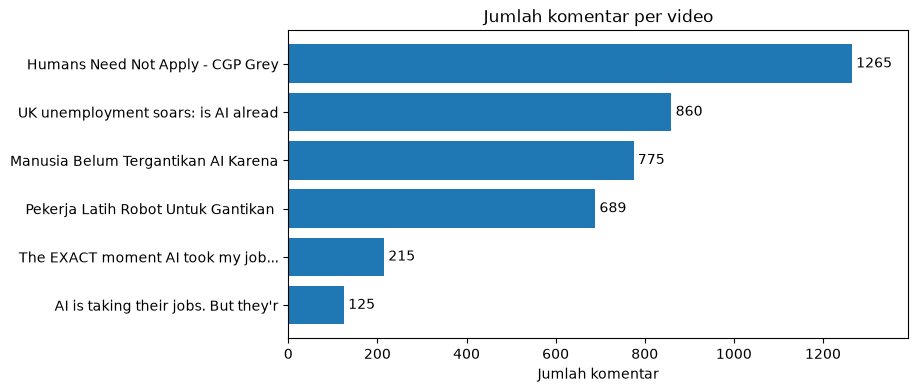

In [50]:
v = df_EDA["video_title"].value_counts().sort_values()

plt.figure(figsize=(8, 4))
batang = plt.barh(v.index.str[:35], v.values)
plt.bar_label(batang, padding=3)          # angka di ujung batang
plt.xlim(0, v.max() * 1.1)                # beri ruang supaya angka tidak terpotong
plt.title("Jumlah komentar per video")
plt.xlabel("Jumlah komentar")
plt.show()

## **4.2 Komposisi Bahasa**

**Sel ini:** menghitung jumlah komentar berbahasa Indonesia dan Inggris lalu menggambarnya sebagai diagram batang.

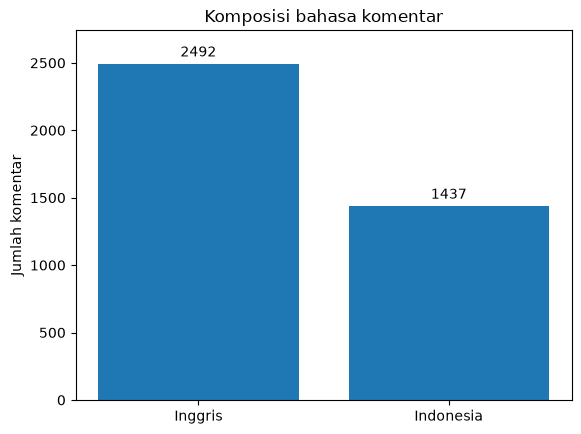

In [51]:
b = df_EDA["bahasa"].value_counts()

batang = plt.bar(b.index, b.values)
plt.bar_label(batang, padding=3)       # angka di atas batang
plt.ylim(0, b.max() * 1.1)             # beri ruang supaya angka tidak terpotong
plt.title("Komposisi bahasa komentar")
plt.ylabel("Jumlah komentar")
plt.show()

## **4.3 Bahasa per Video**

**Sel ini:** menghitung persentase bahasa di setiap video (setiap video dihitung 100%) lalu menggambarnya sebagai batang bertumpuk.

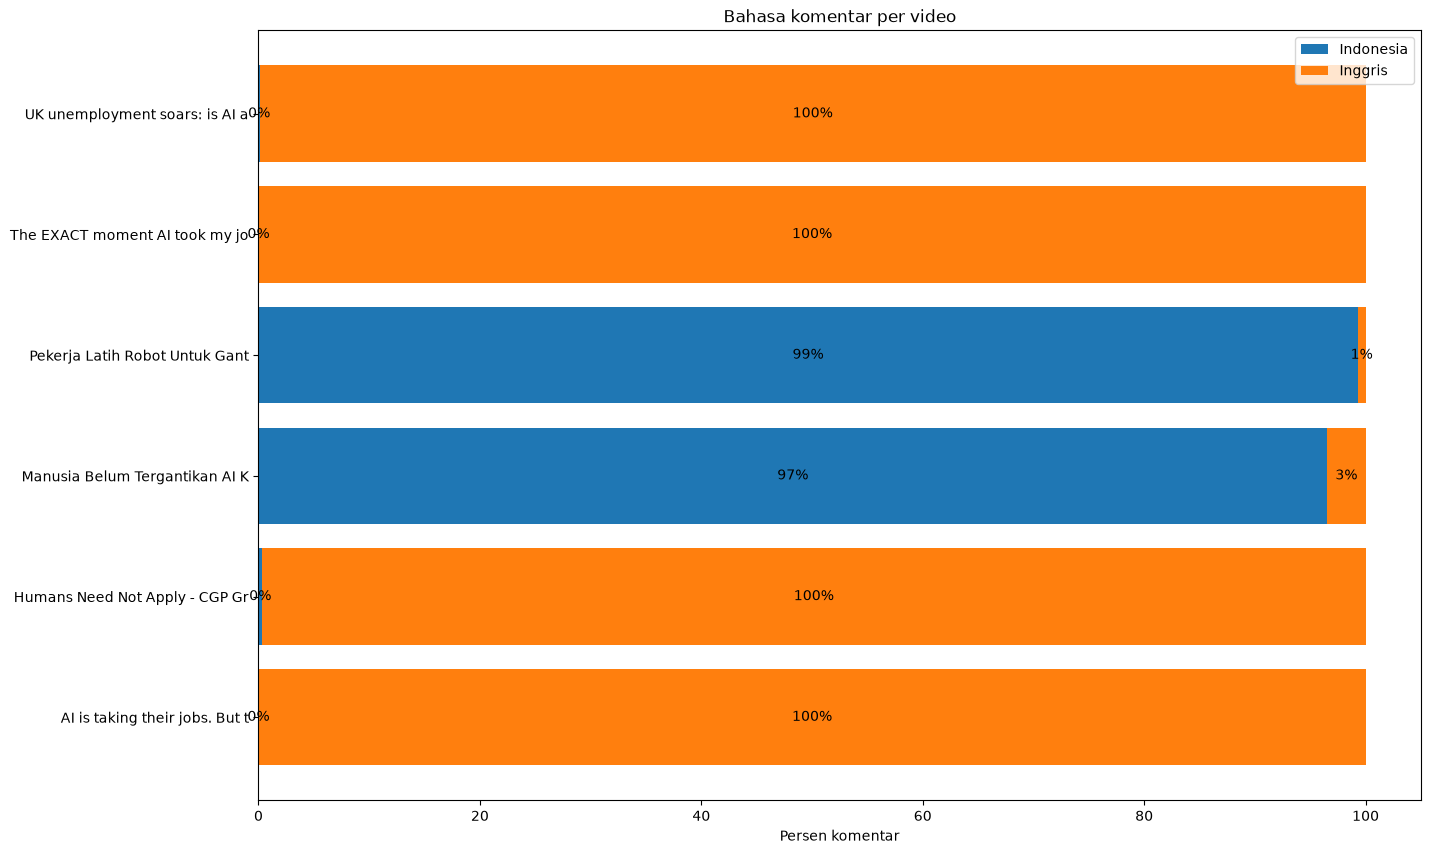

In [52]:
tabel = pd.crosstab(df_EDA["video_title"].str[:30], df_EDA["bahasa"])
persen = tabel.div(tabel.sum(axis=1), axis=0) * 100     # tiap video jadi 100%

kiri = 0
plt.figure(figsize=(15, 10))
for kolom in persen.columns:
    batang = plt.barh(persen.index, persen[kolom], left=kiri, label=kolom)
    plt.bar_label(batang, fmt="%.0f%%", label_type="center")
    kiri = kiri + persen[kolom]
plt.legend()
plt.xlabel("Persen komentar")
plt.title("Bahasa komentar per video")
plt.show()

## **4.4 Panjang Komentar**

Jumlah kata per komentar. Komentar di atas 100 kata dihitung sebagai 100 supaya grafik tetap terbaca.

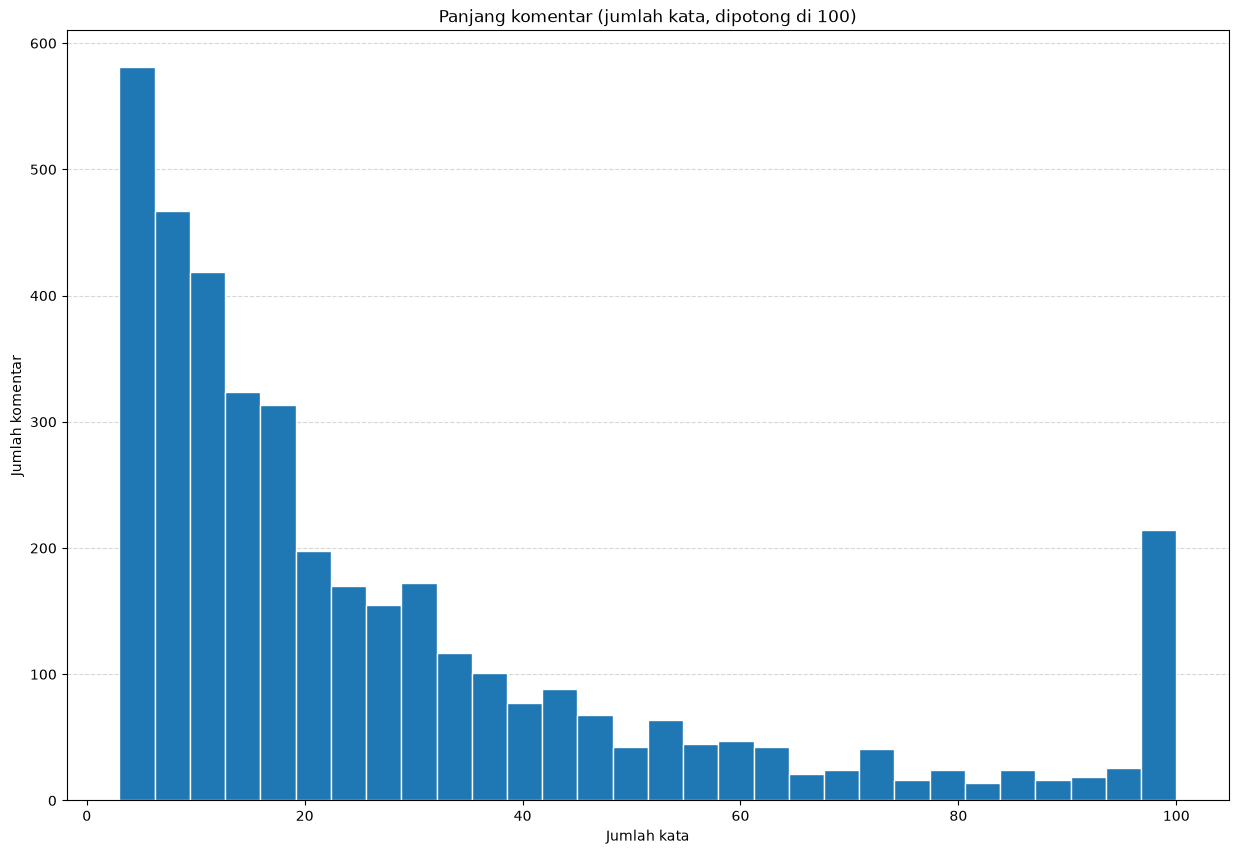

In [53]:
kata = df_EDA["comment"].str.split().str.len().clip(upper=100)

plt.figure(figsize=(15, 10))
plt.hist(kata, bins=30, edgecolor="white")
plt.grid(axis="y", linestyle="--", alpha=0.5)   # garis bantu mendatar
plt.gca().set_axisbelow(True)                   # garis di belakang batang
plt.title("Panjang komentar (jumlah kata, dipotong di 100)")
plt.xlabel("Jumlah kata")
plt.ylabel("Jumlah komentar")
plt.show()

## **4.5 Emoji dan Tanda Baca**

Jumlah komentar yang memuat emoji dan yang memuat tanda `?` atau `!`. Keduanya sering menandai emosi atau pertanyaan, dan karena itu tidak dibuang saat pembersihan teks.

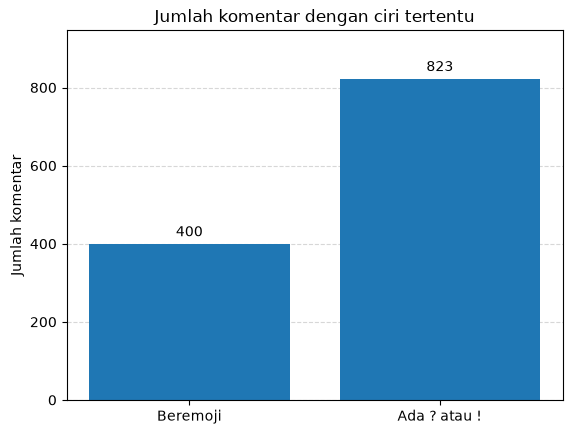

In [54]:
emoji = df_EDA["comment"].str.contains("[\U0001F300-\U0001FAFF\u2600-\u27BF]").sum()
tanda = df_EDA["comment"].str.contains(r"[?!]").sum()

batang = plt.bar(["Beremoji", "Ada ? atau !"], [emoji, tanda])
plt.bar_label(batang, padding=3)
plt.ylim(0, max(emoji, tanda) * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.gca().set_axisbelow(True)
plt.title("Jumlah komentar dengan ciri tertentu")
plt.ylabel("Jumlah komentar")
plt.show()

## **4.6 Sebaran Likes per Komentar**

Likes komentar menunjukkan seberapa banyak penonton setuju dengan komentar itu. Sebarannya sangat miring, jadi likes dikelompokkan supaya grafik tetap terbaca.

Catatan: komentar diambil dengan urutan "popular", jadi komentar yang banyak di-like lebih terwakili daripada keadaan sebenarnya.

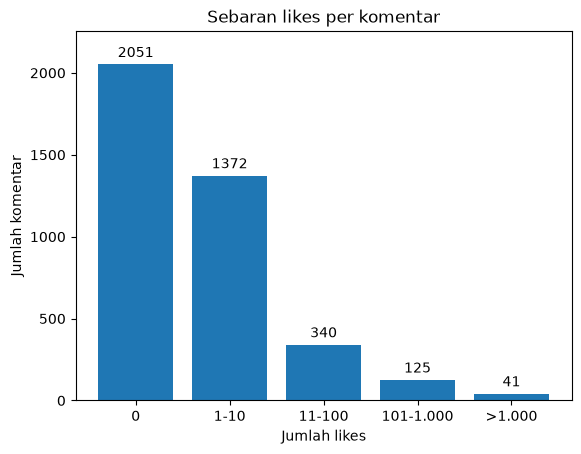

In [55]:
kelompok = pd.cut(df_EDA["likes"], bins=[-1, 0, 10, 100, 1000, float("inf")],
                  labels=["0", "1-10", "11-100", "101-1.000", ">1.000"])
k = kelompok.value_counts().sort_index()

batang = plt.bar(k.index, k.values)
plt.bar_label(batang, padding=3)
plt.ylim(0, k.max() * 1.1)
plt.title("Sebaran likes per komentar")
plt.xlabel("Jumlah likes")
plt.ylabel("Jumlah komentar")
plt.show()

**Hasil:** Lebih dari separuh komentar (52%) tidak mendapat like sama sekali, dan 87% mendapat paling banyak 10 like. Hanya 41 komentar (1%) yang mendapat lebih dari 1.000 like. Artinya, persetujuan penonton terkumpul pada segelintir komentar.

## **4.7 Komentar yang Mendapat Like per Video**

Median likes hampir selalu 0, jadi yang dibandingkan adalah persentase komentar yang mendapat minimal 1 like.

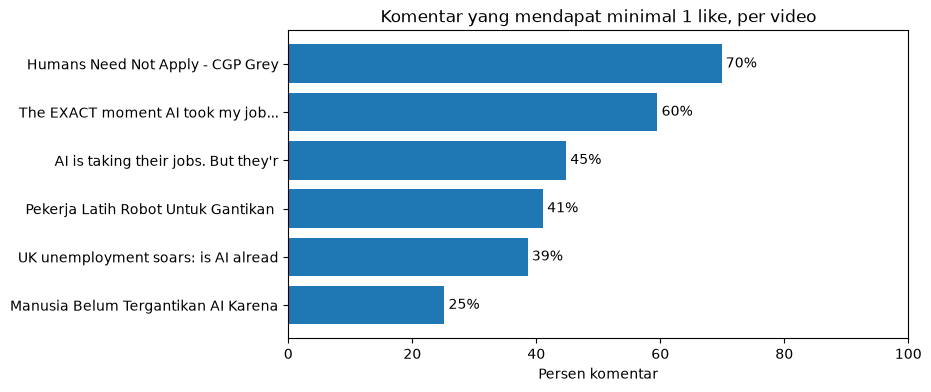

In [56]:
p = (df_EDA["likes"] > 0).groupby(df_EDA["video_title"]).mean().mul(100).sort_values()

plt.figure(figsize=(8, 4))
batang = plt.barh(p.index.str[:35], p.values)
plt.bar_label(batang, fmt="%.0f%%", padding=3)
plt.xlim(0, 100)
plt.title("Komentar yang mendapat minimal 1 like, per video")
plt.xlabel("Persen komentar")
plt.show()

**Hasil:** Komentar di video "Humans Need Not Apply" (CGP Grey) paling sering mendapat like (70%), sedangkan "Manusia Belum Tergantikan AI Karena Satu Hambatan Ini" paling jarang (25%). Angka ini juga dipengaruhi popularitas video, bukan hanya isi komentarnya.

## **4.8 Komentar yang Mendapat Like per Bahasa**

**Sel ini:** menghitung persentase komentar yang mendapat minimal 1 like untuk setiap bahasa.

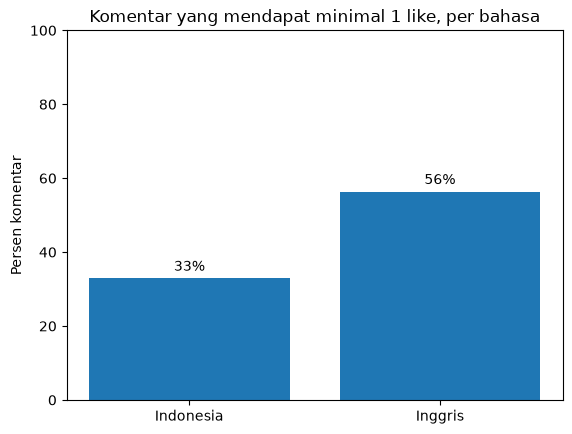

In [57]:
p = (df_EDA["likes"] > 0).groupby(df_EDA["bahasa"]).mean().mul(100)

batang = plt.bar(p.index, p.values)
plt.bar_label(batang, fmt="%.0f%%", padding=3)
plt.ylim(0, 100)
plt.title("Komentar yang mendapat minimal 1 like, per bahasa")
plt.ylabel("Persen komentar")
plt.show()

**Hasil:** Komentar bahasa Inggris lebih sering mendapat like (56%) dibanding bahasa Indonesia (33%). Sebagian besar komentar bahasa Inggris berasal dari video internasional yang jauh lebih populer, jadi perbedaan ini lebih mencerminkan jumlah penonton daripada bahasanya.

## **4.9 10 Komentar dengan Likes Terbanyak**

**Sel ini:** menampilkan 10 komentar dengan likes terbanyak beserta judul video dan bahasanya.

In [58]:
df_EDA.nlargest(10, "likes")[["comment", "likes", "video_title", "bahasa"]]

,comment,likes,video_title,bahasa
1474,"""you might think technology can't replace your job"" I'd be pretty horrified if technology started replacing unemployed peoples jobs.",31000,Humans Need Not Apply - CGP Grey,Inggris
1467,Aged like fine wine,30000,Humans Need Not Apply - CGP Grey,Inggris
1867,I'd really like an updated version of this video.,26000,Humans Need Not Apply - CGP Grey,Inggris
1478,"""The human brain is the most complicated machine, perhaps in the whole universe."" - Human Brain",24000,Humans Need Not Apply - CGP Grey,Inggris
1869,"So you think a bot can take my job? The joke's on you, I don't have a job!",19000,Humans Need Not Apply - CGP Grey,Inggris
1470,"This was 8 years ago, now with the sudden rise of AI music, AI art, AI video, ChatGPT, and so on... that's crazy...",14000,Humans Need Not Apply - CGP Grey,Inggris
1880,New goal: Make it to retirement without being replaced,14000,Humans Need Not Apply - CGP Grey,Inggris
1466,This wouldn't be scary if we lived in a world where being unemployed didn't mean loss of livelihood,13000,Humans Need Not Apply - CGP Grey,Inggris
1464,I was thinking this video was getting out of date… then AI art and language models arrived and I am more concerned about this topic than...,11000,Humans Need Not Apply - CGP Grey,Inggris
1483,"Those darn automation engineers, taking over everyone's jobs. At least I'm safe looks at degree in robotics ... looks at robots that tea...",9800,Humans Need Not Apply - CGP Grey,Inggris


**Hasil:** Kesepuluh komentar teratas semuanya berasal dari video CGP Grey (bahasa Inggris), dengan 9.800 sampai 31.000 like. Isinya didominasi candaan dan kekhawatiran soal pekerjaan yang digantikan teknologi, misalnya "New goal: Make it to retirement without being replaced" (14.000 like).

# **5. Pelabelan (Labeling)**

Komentar bersih dari Bab 3 belum punya label. Pelabelan dilakukan oleh **Claude Opus 5.5** (model AI buatan Anthropic) lewat sesi chat, **bukan lewat kode di notebook ini**, sehingga bab ini hanya berisi penjelasan.

Pelabelan dilakukan dua putaran. Putaran pertama memakai panduan awal. Setelah hasilnya dibandingkan dengan gold set, panduan dipertegas dan seluruh komentar **dilabeli ulang**. Hasil akhirnya disimpan sebagai `youtube_comments_label_claude_v2.csv` di folder `datasets` dan dipakai mulai Bab 6.

## **5.1 Panduan Pelabelan**

Yang dinilai adalah **sikap penulis terhadap AI yang menggantikan pekerjaan manusia**. Panduan akhir yang dipakai:

| Label | Aturan |
|---|---|
| **positif** | Membahas AI, tidak menyalahkan AI, malah mendukung AI atau tidak takut. Termasuk: AI cuma alat, AI masih sering salah atau belum bisa menggantikan manusia, ajakan belajar AI, optimis soal teknologi, dan menyalahkan pajak/regulasi/offshoring (bukan AI) atas hilangnya pekerjaan. |
| **negatif** | Menyalahkan atau takut pada AI. Termasuk: bahaya AI secara umum (Ultron, senjata, AI tak bisa dimatikan, manusia punah), candaan atau deskripsi soal AI/robot yang mengambil pekerjaan walau tanpa kata takut, dan muak pada perusahaan/pemerintah yang melakukan PHK karena AI. |
| **netral** | Membicarakan AI tetapi tidak mengarah ke mana-mana (pertanyaan, info, candaan tanpa soal pekerjaan). Termasuk pertanyaan "siapa yang beli kalau semua diganti AI?". |
| **tidak relevan** | Tidak menyalahkan apa pun dan tidak ada kaitannya dengan AI yang menggantikan atau membantu pekerjaan manusia. Termasuk balasan yang keluar topik walaupun masih di thread AI (debat evolusi, kapitalisme, filsafat, candaan Skynet tanpa konteks kerja). |

## **5.2 Cara Pelabelan**

1. **Bahan acuan.** Claude diberi panduan pelabelan dan contoh komentar dari gold set (150 komentar yang dilabeli manual). Contoh diambil dari bagian **dev** (50 komentar).
2. **Dibagi per kelompok.** Seluruh 3.929 komentar dari `youtube_comments_clean_EDA.csv` dibagi menjadi 20 kelompok berisi 200 komentar (kelompok terakhir 129), lalu dilabeli satu kelompok demi satu kelompok.
3. **Digabung dan dicek.** Setiap komentar harus mendapat tepat satu label yang sah. Untuk 147 komentar yang juga ada di gold set, label manual dari `gold_set_v2.csv` yang dipakai.

## **5.3 Revisi Panduan dan Gold Set**

Label putaran pertama dibandingkan dengan gold set. Banyak ketidakcocokan ternyata berasal dari kasus abu-abu yang belum punya aturan tegas, dan dari label gold yang tidak konsisten antar komentar yang mirip. Karena itu dibuat lima aturan tambahan (sudah masuk ke tabel 5.1):

1. Pertanyaan "siapa yang beli kalau semua diganti AI?" → **netral**.
2. Bahaya AI yang bukan soal pekerjaan (Ultron, nuklir, punah) → **negatif**.
3. Candaan atau deskripsi soal AI/robot yang mengambil pekerjaan → **negatif**.
4. Menyalahkan pajak/regulasi (bukan AI) → **positif**; muak pada perusahaan/pemerintah yang PHK karena AI → **negatif**.
5. Balasan yang keluar topik walaupun masih di thread AI → **tidak relevan**.

Gold set ikut direvisi mengikuti aturan ini dan disimpan sebagai `gold_set_v2.csv` (file lama `gold_set_final.csv` tidak diubah). Ada 26 dari 150 label yang diganti, terbanyak netral → negatif (11 komentar).

| Label | Test lama | Test baru | Dev lama | Dev baru |
|---|---|---|---|---|
| positif | 18 | 13 | 8 | 9 |
| negatif | 23 | 30 | 8 | 14 |
| netral | 25 | 15 | 15 | 8 |
| tidak relevan | 34 | 42 | 19 | 19 |

## **5.4 Uji Kualitas Label**

| Uji | Pelabel | Macro-F1 |
|---|---|---|
| Test (100 komentar, panduan awal, `gold_set_final`) | **Claude Opus 5.5** | **0,595** |
| | Nemotron 3 Ultra *few-shot* (dicoba sebelumnya) | 0,522 |
| Dev (50 komentar, buta, `gold_set_v2`) | **Claude, panduan baru** | **0,683** |
| | Claude, panduan awal | 0,634 |

Uji dev dilakukan oleh dua sesi Claude terpisah yang belum pernah melihat label gold, sehingga hasilnya buta. Panduan baru unggul sekitar 0,05, tetapi selisih itu hanya 3 komentar dari 50 dan sebagian label dev ikut disesuaikan dengan aturan baru, jadi buktinya masih lemah.

## **5.5 Sebaran Label**

| Label | Putaran 1 | Putaran 2 (dipakai) |
|---|---|---|
| positif | 650 (16,5%) | 680 (17,3%) |
| negatif | 988 (25,1%) | **1.203 (30,6%)** |
| netral | 868 (22,1%) | 616 (15,7%) |
| tidak relevan | 1.423 (36,2%) | 1.430 (36,4%) |

Pergeseran terbesar adalah netral → negatif (222 komentar), akibat aturan 2 dan 3 di 5.3. Jika hanya komentar yang membahas AI atau pekerjaan yang dihitung (2.499 komentar), sikap **negatif paling banyak (48,1%)**, disusul positif (27,2%) dan netral (24,6%). Artinya, hampir separuh publik yang membahas isu ini merasa khawatir atau menolak AI yang menggantikan pekerjaan.

## **5.6 Keterbatasan**

- Label dibuat oleh AI, bukan manusia, sehingga sebaran di atas adalah **perkiraan**. Kualitas label juga menjadi batas atas kinerja model klasifikasi di Bab 8.
- Komentar yang lebih dari 600 karakter hanya dibaca 600 karakter pertamanya saat dilabeli.
- Pelabelan dilakukan dalam sesi chat, jadi tidak bisa diulang persis dengan menjalankan notebook. File hasilnya disimpan sebagai bukti.
- Aturan baru ditemukan dengan melihat ketidakcocokan di bagian test, sehingga bagian test tidak lagi sepenuhnya independen. Gold set juga dilabeli oleh satu orang.

# **6. Text Preprocessing**

Bab 3 hanya membersihkan data mentah. Bab ini mengolah **teks komentar** supaya siap dibaca model klasik: 6.2 case folding → 6.3 removing → 6.4 filtering (stopword) → 6.5 tokenizing → 6.6 stemming.

Hasil olahan disimpan di kolom baru `teks` (dan `token`), sedangkan kolom `comment` tetap asli karena dipakai oleh model deep learning dan embedding e5 di Bab 8.

## **6.1 Memuat Data Berlabel**

Mengenali data berlabel hasil Bab 5: berapa barisnya, kolom apa saja, dan bagaimana sebaran labelnya.

**Sel ini:** memuat data berlabel `youtube_comments_label_claude_v2.csv` ke tabel `df`. Lokasi berkas dicari otomatis, jadi sel yang sama bisa dijalankan di Google Colab maupun laptop.

In [2]:
# Lokasi data: Google Colab atau laptop
for path in ["/content/youtube_comments_label_claude_v2.csv", "../../datasets/youtube_comments_label_claude_v2.csv", "datasets/youtube_comments_label_claude_v2.csv"]:
    if os.path.exists(path):
        break

df = pd.read_csv(path)
print("Data dimuat dari:", path)
df.head()

Data dimuat dari: ../../datasets/youtube_comments_label_claude_v2.csv


,video_title,comment,likes,author_id,bahasa,label
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Bahas imigrant maroko yg nyebrang ke spanyol d...,413,0,Indonesia,tidak relevan
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Menurut saya jika semua pengusaha berpikiran s...,189,1,Indonesia,negatif
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,jujur ya sebagai seorang yang bekerja di bidan...,6,2,Indonesia,negatif
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Gw sebagai illustrator susah bener dapet klien...,588,3,Indonesia,negatif
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIA...,Niat untung -> efesiensi phk->produksi meningk...,85,4,Indonesia,netral


**Sel ini:** menampilkan jumlah baris, kolom, dan tipe data.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3929 entries, 0 to 3928
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   video_title  3929 non-null   str  
 1   comment      3929 non-null   str  
 2   likes        3929 non-null   int64
 3   author_id    3929 non-null   int64
 4   bahasa       3929 non-null   str  
 5   label        3929 non-null   str  
dtypes: int64(2), str(4)
memory usage: 1.1 MB


**Sel ini:** menghitung jumlah komentar untuk setiap label.

In [4]:
df["label"].value_counts()

label
tidak relevan    1430
negatif          1203
positif           680
netral            616
Name: count, dtype: int64

**Hasil:**

- Ada **3.929 komentar** dan 6 kolom, **tidak ada nilai kosong**.
- Kolom yang dipakai untuk klasifikasi hanya dua: `comment` (teks) dan `label` (jawaban).
- Sebaran label: tidak relevan 1.430, negatif 1.203, positif 680, netral 616. Netral paling sedikit (15,7%), jadi perlu diperhatikan saat klasifikasi.
- Bahasa: Inggris 2.492 komentar, Indonesia 1.437 komentar.

## **6.2 Case Folding**

Semua huruf diubah menjadi huruf kecil, supaya "AI", "Ai", dan "ai" dianggap kata yang sama. Hasilnya disimpan di kolom baru `teks`, sedangkan `comment` tetap asli.

**Sel ini:** menghitung komentar yang masih punya huruf besar.

In [5]:
# Cek: berapa komentar yang masih punya huruf besar
(df["comment"] != df["comment"].str.lower()).sum()

np.int64(3405)

**Sel ini:** mengubah semua huruf menjadi huruf kecil dan menyimpannya di kolom `teks`.

In [6]:
df["teks"] = df["comment"].str.lower()
df[["comment", "teks"]].head()

,comment,teks
0,Bahas imigrant maroko yg nyebrang ke spanyol d...,bahas imigrant maroko yg nyebrang ke spanyol d...
1,Menurut saya jika semua pengusaha berpikiran s...,menurut saya jika semua pengusaha berpikiran s...
2,jujur ya sebagai seorang yang bekerja di bidan...,jujur ya sebagai seorang yang bekerja di bidan...
3,Gw sebagai illustrator susah bener dapet klien...,gw sebagai illustrator susah bener dapet klien...
4,Niat untung -> efesiensi phk->produksi meningk...,niat untung -> efesiensi phk->produksi meningk...


**Hasil:** 3.405 dari 3.929 komentar punya huruf besar, dan sekarang semuanya sudah menjadi huruf kecil di kolom `teks`.

## **6.3 Removing**

Membuang bagian teks yang tidak dipakai model: URL, angka, tanda baca, karakter khusus (emoji dan simbol), dan spasi berlebih. Setiap jenis **dicek dulu**, lalu **hanya dibersihkan kalau ada**.

**Sel ini:** menyiapkan pola untuk setiap jenis yang akan dibuang, lalu menghitung berapa komentar yang mengandungnya.

In [7]:
pola = {
    "URL": r"https?://\S+|www\.\S+",
    "angka": r"\d",
    "tanda baca": "[" + re.escape(string.punctuation) + "]",
    "karakter khusus (emoji, simbol)": r"[^a-z0-9\s" + re.escape(string.punctuation) + "]",
    "spasi berlebih": r"\s{2,}|^\s|\s$",
}

# Cek: berapa komentar yang mengandung setiap jenis
cek_removing = lambda: pd.Series({nama: df["teks"].str.contains(p).sum() for nama, p in pola.items()})
cek_removing()

URL                                   0
angka                               694
tanda baca                         3285
karakter khusus (emoji, simbol)     677
spasi berlebih                        0
dtype: int64

**Sel ini:** membersihkan jenis yang ditemukan (diganti spasi supaya kata tidak menempel), lalu merapikan spasi.

In [8]:
# Bersihkan hanya jenis yang ada (diganti spasi supaya kata tidak menempel)
for nama, p in pola.items():
    if nama != "spasi berlebih" and df["teks"].str.contains(p).sum() > 0:
        df["teks"] = df["teks"].str.replace(p, " ", regex=True)
        print("dibersihkan:", nama)

# Terakhir, rapikan spasi berlebih yang muncul setelah pembersihan
df["teks"] = df["teks"].str.split().str.join(" ")

dibersihkan: angka
dibersihkan: tanda baca
dibersihkan: karakter khusus (emoji, simbol)


**Sel ini:** mengecek ulang. Semua jenis harus bernilai `0`.

In [9]:
# Cek ulang: semua harus 0
cek_removing()

URL                                0
angka                              0
tanda baca                         0
karakter khusus (emoji, simbol)    0
spasi berlebih                     0
dtype: int64

**Sel ini:** menampilkan contoh teks sebelum dan sesudah dibersihkan.

In [10]:
df[["comment", "teks"]].head()

,comment,teks
0,Bahas imigrant maroko yg nyebrang ke spanyol d...,bahas imigrant maroko yg nyebrang ke spanyol d...
1,Menurut saya jika semua pengusaha berpikiran s...,menurut saya jika semua pengusaha berpikiran s...
2,jujur ya sebagai seorang yang bekerja di bidan...,jujur ya sebagai seorang yang bekerja di bidan...
3,Gw sebagai illustrator susah bener dapet klien...,gw sebagai illustrator susah bener dapet klien...
4,Niat untung -> efesiensi phk->produksi meningk...,niat untung efesiensi phk produksi meningkat t...


**Hasil:**

| Jenis | Sebelum | Sesudah |
|---|---|---|
| URL | 0 (sudah dibersihkan di Bab 3) | 0 |
| angka | 694 | 0 |
| tanda baca | 3.285 | 0 |
| karakter khusus (emoji, simbol) | 677 | 0 |
| spasi berlebih | 0 (sudah dirapikan di Bab 3) | 0 |

Tidak ada komentar yang menjadi kosong setelah dibersihkan.

## **6.4 Filtering (Stopword Removal)**

Membuang kata umum yang tidak membawa makna, misalnya "yang", "dan", "the", "is". Daftarnya gabungan stopword bahasa Indonesia (Sastrawi) dan bahasa Inggris (scikit-learn).

**Kata negasi tetap disimpan**, karena membalik makna kalimat: "AI **tidak** akan menggantikan pekerjaan" berbeda jauh dengan "AI akan menggantikan pekerjaan".

**Sel ini:** menyusun daftar stopword (tanpa kata negasi), lalu menghitung komentar yang mengandung stopword.

In [11]:
stopword = set(StopWordRemoverFactory().get_stop_words()) | set(ENGLISH_STOP_WORDS)
negasi = {"tidak", "belum", "nggak", "not", "no", "nor", "never", "nothing", "none", "cannot"}
stopword = stopword - negasi
print("Jumlah stopword:", len(stopword))

# Cek: berapa komentar yang mengandung stopword
df["teks"].apply(lambda t: any(kata in stopword for kata in t.split())).sum()

Jumlah stopword: 431


np.int64(3714)

**Sel ini:** membuang stopword dari setiap komentar dan membandingkan rata-rata jumlah kata sebelum dan sesudahnya.

In [12]:
sebelum = df["teks"].str.split().str.len().mean()
df["teks"] = df["teks"].apply(lambda t: " ".join(kata for kata in t.split() if kata not in stopword))
print(f"Rata-rata jumlah kata per komentar: {sebelum:.1f} -> {df['teks'].str.split().str.len().mean():.1f}")

Rata-rata jumlah kata per komentar: 30.9 -> 18.0


**Sel ini:** membuang komentar yang menjadi kosong karena isinya stopword semua.

In [13]:
# Komentar yang isinya stopword semua menjadi kosong, jadi dibuang
print("Komentar kosong:", (df["teks"] == "").sum())
df = df[df["teks"] != ""].reset_index(drop=True)
print("Sisa data:", len(df))

Komentar kosong: 8
Sisa data: 3921


**Hasil:**

- 3.714 komentar mengandung stopword, dan 431 stopword dibuang dari teks.
- Rata-rata komentar menyusut dari 30,9 kata menjadi 18,0 kata (sekitar 42% kata terbuang).
- 8 komentar menjadi kosong karena isinya stopword semua (misalnya "Indeed, it was" dan "always have been"), jadi dibuang. **Sisa data: 3.921 komentar.**

## **6.5 Tokenizing**

Memecah setiap komentar menjadi daftar kata (token). Contoh: `"ai tidak butuh makan"` → `["ai", "tidak", "butuh", "makan"]`. Hasilnya disimpan di kolom `token`.

**Sel ini:** memecah teks menjadi token, lalu menghitung jumlah token dan kata unik.

In [14]:
df["token"] = df["teks"].str.split()

semua_token = [kata for daftar in df["token"] for kata in daftar]
print("Jumlah token:", len(semua_token))
print("Jumlah kata unik:", len(set(semua_token)))
df[["teks", "token"]].head()

Jumlah token: 70647
Jumlah kata unik: 13627


,teks,token
0,bahas imigrant maroko yg nyebrang spanyol donk...,"[bahas, imigrant, maroko, yg, nyebrang, spanyo..."
1,semua pengusaha berpikiran sama mengganti manu...,"[semua, pengusaha, berpikiran, sama, mengganti..."
2,jujur seorang bekerja bidang desain seni ilust...,"[jujur, seorang, bekerja, bidang, desain, seni..."
3,gw illustrator susah bener dapet klien baru or...,"[gw, illustrator, susah, bener, dapet, klien, ..."
4,niat untung efesiensi phk produksi meningkat t...,"[niat, untung, efesiensi, phk, produksi, menin..."


**Hasil:** 3.921 komentar dipecah menjadi **70.647 token** dengan **13.627 kata unik**. Kata unik inilah yang nanti menjadi kolom-kolom fitur di TF-IDF.

## **6.6 Stemming**

Mengubah setiap kata ke bentuk dasarnya, supaya kata yang maknanya sama dihitung sebagai satu kata. Contoh: "pengusaha" → "usaha", "mengganti" → "ganti", "approaching" → "approach".

Stemmer dipilih sesuai bahasa komentar: **Sastrawi** untuk bahasa Indonesia dan **Porter** untuk bahasa Inggris. Proses ini memakan waktu sekitar 2-3 menit.

**Sel ini:** menjalankan stemming sesuai bahasa komentar, lalu menyusun ulang kolom `teks` dari token hasil stemming.

In [15]:
stem_id = StemmerFactory().create_stemmer()   # bahasa Indonesia
stem_en = PorterStemmer()                      # bahasa Inggris
unik_sebelum = len({kata for daftar in df["token"] for kata in daftar})

df["token"] = [
    [stem_id.stem(kata) if bahasa == "Indonesia" else stem_en.stem(kata) for kata in token]
    for token, bahasa in zip(df["token"], df["bahasa"])
]
df["teks"] = df["token"].str.join(" ")         # teks akhir untuk TF-IDF

print("Kata unik:", unik_sebelum, "->", len({kata for daftar in df["token"] for kata in daftar}))
df[["comment", "teks"]].head()

Kata unik: 13627 -> 9848


,comment,teks
0,Bahas imigrant maroko yg nyebrang ke spanyol d...,bahas imigrant maroko yg nyebrang spanyol donk...
1,Menurut saya jika semua pengusaha berpikiran s...,semua usaha pikir sama ganti manusia ai potong...
2,jujur ya sebagai seorang yang bekerja di bidan...,jujur orang kerja bidang desain seni ilustrato...
3,Gw sebagai illustrator susah bener dapet klien...,gw illustrator susah bener dapet klien baru or...
4,Niat untung -> efesiensi phk->produksi meningk...,niat untung efesiensi phk produksi tingkat tid...


**Hasil:** jumlah kata unik turun dari 13.627 menjadi **9.848** (sekitar 28% lebih sedikit), karena kata-kata berimbuhan digabung ke kata dasarnya. Contoh: "semua pengusaha berpikiran sama mengganti manusia" → "semua usaha pikir sama ganti manusia".

Catatan: stemmer bahasa Inggris (Porter) kadang menghasilkan potongan yang bukan kata utuh, misalnya "replacing" → "replac". Ini wajar, karena yang penting kata-kata sejenis menjadi sama.

# **7. Ekstraksi Fitur**

Model tidak bisa membaca kata, jadi setiap komentar diubah menjadi deretan angka (fitur). Urutannya: 7.1 pembagian data → 7.2 skema label → 7.3 TF-IDF → 7.4 word embedding FastText.

## **7.1 Pembagian Data Latih dan Uji**

Data **dibagi dulu** sebelum fitur dibuat: 80% data latih dan 20% data uji. Pembagian memakai keempat label asli supaya proporsi data uji sama dengan data aslinya. TF-IDF dan FastText hanya belajar dari data latih, supaya data uji benar-benar belum pernah dilihat.

**Sel ini:** membagi data menjadi 80% latih dan 20% uji dengan proporsi label yang sama.

In [16]:
df_train, df_test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["label"])
X_train, X_test = df_train["teks"], df_test["teks"]
y_train, y_test = df_train["label"], df_test["label"]
print("Data latih:", len(X_train), "| data uji:", len(X_test))

Data latih: 3136 | data uji: 785


## **7.2 Skema Label (Menyederhanakan Label)**

### **Masalah: 4 label terlalu kabur**

Dengan 4 label (positif, negatif, netral, tidak relevan), model terbaik hanya mencapai macro-F1 sekitar **0,58**. Setelah kesalahannya diperiksa, sumber masalahnya ternyata ada pada label, bukan pada model:

- **Netral dan tidak relevan paling sering tertukar.** Model hanya menangkap 37% komentar netral.
- **Manusia pun sering berbeda pendapat.** Di gold set, komentar yang mirip kadang diberi label berbeda. Contohnya pertanyaan "siapa yang beli kalau semua diganti AI?" pernah diberi label positif, netral, dan negatif.
- **Banyak komentar berupa sindiran atau candaan**, misalnya "Robots will take your unemployment", sehingga sulit dipahami manusia maupun mesin.

Semakin jelas dan sempit batas antar-label, semakin mudah model belajar. Karena itu label disederhanakan.

### **Solusi: gabungkan label yang kabur menjadi "perlu ditinjau"**

Netral dan tidak relevan digabung menjadi satu label, **perlu ditinjau**: komentar yang tidak jelas sikapnya dan perlu dianalisis lebih lanjut oleh manusia. Labelnya tinggal 3:

| Label | Arti |
|---|---|
| **positif** | tidak takut atau mendukung AI |
| **negatif** | takut, menolak, atau menyalahkan AI |
| **perlu ditinjau** | sikapnya tidak jelas atau tidak membahas AI dan pekerjaan |

Data uji tetap memakai **semua** komentar dengan 3 label ini, supaya skornya jujur dan mencerminkan kondisi nyata.

### **Dua cara melatih model**

| | Skema A | Skema B |
|---|---|---|
| **Data latih** | hanya positif dan negatif (batas paling jelas) | semua komentar latih dengan 3 label |
| **Asal label "perlu ditinjau"** | dari **keraguan** model: kalau peluang positif di antara 0,3 dan 0,7, komentar dianggap perlu ditinjau | model **belajar langsung** dari contoh komentar yang perlu ditinjau |
| **Ambang keyakinan** | awalnya 0,7, lalu dicari yang terbaik di Bab 9 | tidak perlu |

Cara kerja ambang pada skema A:

| Peluang positif | Keputusan |
|---|---|
| ≥ 0,7 | **positif** |
| ≤ 0,3 | **negatif** |
| di antara keduanya (model ragu) | **perlu ditinjau** |

**Label encoding:** untuk skema A, label diubah menjadi angka **positif = 1** dan **negatif = 0**.

### **Hasil singkat (detail di Bab 9)**

- **Skema A tidak berhasil** (macro-F1 terbaik 0,463), karena model yang **yakin belum tentu komentarnya relevan**. Model tidak pernah melihat komentar netral atau tidak relevan saat latihan, sehingga komentar seperti "Terima kasih koko" tetap bisa ditebak positif dengan yakin.
- **Skema B berhasil** (macro-F1 **0,646**, akurasi 0,699), lebih tinggi daripada versi 4 label (0,582). Karena itu **skema B dipakai sebagai model akhir**.
- Skor 3 label tidak sepenuhnya setara dengan skor 4 label, karena tugas 3 label memang lebih mudah. Yang adil dibandingkan adalah skema A dan skema B, karena keduanya diuji pada data uji yang sama.

**Sel ini:** menyiapkan data latih skema A (positif dan negatif saja) dan jawaban data uji dengan 3 label.

In [17]:
# Penyederhanaan label: netral dan tidak relevan sering tertukar (bahkan bagi manusia),
# jadi keduanya digabung menjadi satu label "perlu ditinjau" = perlu dianalisis lebih lanjut oleh manusia.
TINJAU = "perlu ditinjau"
ke_3 = lambda label: np.where(np.isin(label, ["positif", "negatif"]), label, TINJAU)   # netral & tidak relevan -> perlu ditinjau

# Skema A: model hanya belajar dari positif & negatif, karena batas keduanya paling jelas
maska_2 = df_train["label"].isin(["positif", "negatif"]).values   # baris latih yang dipakai skema A
df_train_2 = df_train[maska_2]
y_train_2 = (df_train_2["label"] == "positif").astype(int).values  # label encoding: positif = 1, negatif = 0
# Skema B dan cross-validation memakai semua komentar latih dengan 3 label
y_train_3 = ke_3(df_train["label"].values)                          # 3 label untuk menilai cross-validation di Bab 9
# Data uji selalu memakai SEMUA komentar dengan 3 label, supaya skornya jujur
y_test_3 = ke_3(df_test["label"].values)                            # jawaban data uji: 3 label

print("Latih skema A:", len(df_train_2), "komentar", df_train_2["label"].value_counts().to_dict())
print("Uji:", len(df_test), "komentar", pd.Series(y_test_3).value_counts().to_dict())

Latih skema A: 1506 komentar {'negatif': 962, 'positif': 544}


Uji: 785 komentar {'perlu ditinjau': 408, 'negatif': 241, 'positif': 136}


**Sel ini:** fungsi bantu. `peluang` menghitung peluang positif, `ke_label` mengubah peluang menjadi 3 label dengan ambang keyakinan, dan `nilai` menyimpan skor setiap model ke tabel perbandingan.

In [18]:
AMBANG = 0.7   # keyakinan minimal; di bawah ini komentar dianggap "perlu ditinjau"


def peluang(model, X):
    """Peluang komentar berlabel positif (0-1)."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return 1 / (1 + np.exp(-model.decision_function(X)))   # SVM tidak punya peluang, skornya diubah ke 0-1


def ke_label(p, ambang=AMBANG):
    """Yakin positif, yakin negatif, atau perlu ditinjau."""
    # Contoh dengan ambang 0,7: peluang 0,85 -> positif | 0,20 -> negatif | 0,55 -> model ragu -> perlu ditinjau
    return np.where(p >= ambang, "positif", np.where(p <= 1 - ambang, "negatif", TINJAU))


hasil, prediksi = [], {}   # tabel perbandingan dan tebakan setiap model


def nilai(fitur, nama_model, pred):
    """Simpan tebakan dan skornya terhadap data uji 3 label."""
    prediksi[(fitur, nama_model)] = pred
    hasil.append({"Fitur": fitur, "Model": nama_model,
                  "Akurasi": round(accuracy_score(y_test_3, pred), 3),
                  "Macro-F1": round(f1_score(y_test_3, pred, average="macro"), 3),
                  "Perlu ditinjau (%)": round((pred == TINJAU).mean() * 100, 1)})

**Hasil:**

- Data latih skema A berisi **1.506 komentar** (negatif 962, positif 544). Netral dan tidak relevan (1.630 komentar) tidak dipakai untuk melatih skema A.
- Data uji tetap **785 komentar**: perlu ditinjau 408 (52%), negatif 241, dan positif 136. Jadi lebih dari separuh data uji adalah komentar yang seharusnya diserahkan ke manusia.

## **7.3 TF-IDF**

**TF-IDF** memberi nilai tinggi pada kata yang sering muncul di sebuah komentar tetapi jarang muncul di komentar lain, sehingga kata yang khas mendapat bobot lebih besar daripada kata yang umum.

**Sel ini:** melatih TF-IDF pada data latih skema A, mengubah data latih dan uji menjadi angka, lalu menampilkan 10 kata dengan bobot rata-rata tertinggi.

In [19]:
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(df_train_2["teks"])   # belajar kosakata dari data latih saja
X_test_tfidf = tfidf.transform(df_test["teks"])
print("Ukuran fitur latih:", X_train_tfidf.shape, "| uji:", X_test_tfidf.shape)

# 10 kata dengan rata-rata bobot TF-IDF tertinggi
pd.Series(X_train_tfidf.mean(axis=0).A1, index=tfidf.get_feature_names_out()).nlargest(10)

Ukuran fitur latih: (1506, 6428) | uji: (785, 6428)


ai         0.053417
job        0.028025
manusia    0.024999
not        0.021305
robot      0.020343
human      0.017793
kerja      0.016687
peopl      0.016616
yg         0.016459
no         0.014035
dtype: float64

**Hasil:**

- Setiap komentar sekarang diwakili **6.428 angka**. Kosakatanya lebih sedikit daripada sebelumnya karena TF-IDF hanya belajar dari 1.506 komentar positif dan negatif.
- Kata dengan bobot rata-rata tertinggi adalah "ai", "job", "manusia", "not", dan "robot". Kata negasi "not" dan "no" ikut penting karena tidak dibuang di 6.4.

## **7.4 Word Embedding (FastText)**

TF-IDF hanya menghitung kata, jadi "takut" dan "khawatir" dianggap tidak berhubungan. **Word embedding** mengubah setiap kata menjadi deretan angka yang mewakili maknanya, sehingga kata yang sering muncul dalam konteks serupa mendapat angka yang mirip.

| Metode | Cara belajar | Kata baru / salah ketik |
|---|---|---|
| Word2Vec | dari kata-kata di sekitarnya | tidak bisa |
| GloVe | dari hitungan kata yang muncul bersama di seluruh data | tidak bisa |
| **FastText** | seperti Word2Vec, tetapi juga dari **potongan huruf** di dalam kata | **bisa** |

**FastText dipilih** karena komentar YouTube penuh kata gaul dan salah ketik ("bangettt", "pekerjaaan"). Karena belajar dari potongan huruf, FastText tetap bisa memberi angka untuk kata yang belum pernah dilihat.

FastText dilatih dari **data latih saja**. Setiap komentar lalu diwakili oleh **rata-rata** vektor kata-katanya (100 angka per komentar).

**Sel ini:** melatih FastText dari token seluruh data latih. FastText tidak memakai label, jadi semua komentar latih boleh dipakai supaya kosakatanya lebih banyak.

In [20]:
ft = FastText(sentences=df_train["token"].tolist(), vector_size=100, window=5, min_count=2, epochs=20, seed=SEED, workers=1)
print("Jumlah kata di kosakata FastText:", len(ft.wv))

Jumlah kata di kosakata FastText: 4388


**Sel ini:** mengubah setiap komentar menjadi rata-rata vektor kata-katanya.

In [21]:
def rata_vektor(token):
    return np.mean([ft.wv[kata] for kata in token], axis=0)

X_train_ft = np.vstack(df_train_2["token"].apply(rata_vektor))
X_test_ft = np.vstack(df_test["token"].apply(rata_vektor))
print("Ukuran fitur latih:", X_train_ft.shape, "| uji:", X_test_ft.shape)

Ukuran fitur latih: (1506, 100) | uji: (785, 100)


**Sel ini:** menampilkan 5 kata yang paling mirip untuk beberapa kata contoh, sebagai cek apakah FastText sudah menangkap makna.

In [22]:
# Kata yang dianggap paling mirip oleh FastText
for kata in ["job", "kerja", "takut"]:
    print(kata, "->", [mirip for mirip, _ in ft.wv.most_similar(kata, topn=5)])

job -> ['lost', 'got', 'receiv', 'house', 'loss']
kerja -> ['semua', 'ngegantiin', 'gantiin', 'hasil', 'alat']
takut -> ['aplikasi', 'operasi', 'eksploitasi', 'masyarakat', 'bentar']


**Hasil:**

- FastText mempelajari 4.388 kata dari seluruh data latih, dan setiap komentar diwakili **100 angka**.
- Sebagian kata mirip sudah masuk akal, misalnya "job" dekat dengan "lost" dan "loss". Namun kebanyakan masih acak (misalnya "takut" dekat dengan "aplikasi" dan "operasi"), karena FastText hanya belajar dari 3.136 komentar.

# **8. Klasifikasi**

Setiap model belajar dari data latih skema A (**positif dan negatif**), lalu menebak **semua** komentar data uji. Tebakan diubah menjadi 3 label dengan ambang 0,7 (lihat 7.2), lalu dibandingkan dengan jawaban sebenarnya memakai **akurasi** dan **macro-F1** (rata-rata F1 ketiga label, setiap label dianggap sama penting). Kolom **"Perlu ditinjau (%)"** menunjukkan berapa persen komentar uji yang diserahkan ke manusia.

Supaya negatif yang lebih banyak tidak mendominasi, model memakai `class_weight="balanced"`: kesalahan pada kelas kecil dihitung lebih berat. Cara ini dipilih daripada SMOTE karena tidak membuat data buatan.

## **8.1 Model Klasik**

Tujuh model dicoba dengan dua jenis fitur: TF-IDF (7.3) dan FastText (7.4). KNN menebak label dari 15 komentar yang paling mirip. Naive Bayes hanya memakai TF-IDF, karena Multinomial Naive Bayes hanya bisa menerima angka positif, sedangkan vektor FastText bisa bernilai negatif.

**Sel ini:** melatih setiap model dengan setiap jenis fitur, lalu menampilkan skor 3 label pada data uji, diurutkan dari yang terbaik.

In [23]:
model_klasik = {
    "Naive Bayes": MultinomialNB(),
    "SVM": LinearSVC(class_weight="balanced", random_state=SEED),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "KNN": KNeighborsClassifier(n_neighbors=15, metric="cosine", weights="distance"),
}
fitur = {"TF-IDF": (X_train_tfidf, X_test_tfidf), "FastText": (X_train_ft, X_test_ft)}

for nama_fitur, (X_tr, X_te) in fitur.items():
    for nama_model, model in model_klasik.items():
        if nama_model == "Naive Bayes" and nama_fitur == "FastText":
            continue
        nilai(nama_fitur, nama_model, ke_label(peluang(model.fit(X_tr, y_train_2), X_te)))

pd.DataFrame(hasil).sort_values("Macro-F1", ascending=False).reset_index(drop=True)

,Fitur,Model,Akurasi,Macro-F1,Perlu ditinjau (%)
0,TF-IDF,KNN,0.479,0.370,63.2
1,TF-IDF,Naive Bayes,0.488,0.355,45.4
2,TF-IDF,SVM,0.540,0.333,91.6
3,TF-IDF,Random Forest,0.400,0.325,60.4
4,FastText,Random Forest,0.441,0.321,72.4
5,TF-IDF,Extra Trees,0.373,0.314,44.8
6,TF-IDF,Logistic Regression,0.536,0.311,94.8
7,FastText,KNN,0.411,0.295,65.1
8,FastText,Extra Trees,0.373,0.289,52.6
9,TF-IDF,Decision Tree,0.292,0.257,0.0


**Hasil:**

- Skor skema A dengan model klasik **rendah**: yang terbaik hanya TF-IDF + KNN (macro-F1 **0,370**), disusul Naive Bayes (0,355) dan SVM (0,333).
- Dengan ambang 0,7, SVM dan Logistic Regression terlalu ragu: 92-95% komentar uji jatuh ke "perlu ditinjau". Sebaliknya, Decision Tree tidak pernah ragu (0%), karena peluang yang dihasilkannya selalu 0 atau 1.
- Artinya, ambang 0,7 belum cocok untuk semua model. Ambang terbaik untuk setiap model dicari di Bab 9.

## **8.2 Deep Learning (Fine-tuning)**

Model *pre-trained* multibahasa dilatih ulang (*fine-tuning*) memakai data latih yang sama. Model ini sudah "membaca" teks dalam 100 bahasa sebelumnya, jadi ia memahami konteks kalimat, bukan hanya menghitung kata.

- **XLM-RoBERTa-base**: model multibahasa yang paling umum dipakai untuk klasifikasi teks.
- **DistilBERT multilingual**: versi lebih kecil dan cepat.

Model deep learning memakai kolom `comment` (teks asli), karena tokenizer-nya sendiri sudah dirancang untuk teks utuh. mDeBERTa-v3 tidak dipakai karena *loss*-nya menjadi `NaN` saat dilatih di lingkungan ini. Supaya muat di GPU 6 GB, **lapisan embedding (kamus kata model) dibekukan** dan hanya lapisan di atasnya yang dilatih. *Learning rate* dinaikkan perlahan di awal pelatihan (*warmup*), karena XLM-RoBERTa kadang gagal belajar bila langsung memakai *learning rate* penuh. Pelatihan berjalan di GPU, sekitar 3-6 menit per model.

**Sel ini:** mendefinisikan fungsi `fine_tune` yang melatih model *pre-trained* pada data latih skema A, lalu mengembalikan peluang positif untuk setiap komentar uji.

In [24]:
perangkat = "cuda" if torch.cuda.is_available() else "cpu"


def fine_tune(nama_model, epoch=3, batch=8):
    """Latih model pre-trained dengan positif & negatif, lalu hitung peluang positif data uji."""
    torch.manual_seed(SEED)
    tok = AutoTokenizer.from_pretrained(nama_model)
    model = AutoModelForSequenceClassification.from_pretrained(nama_model, num_labels=2).to(perangkat)
    for param in model.base_model.embeddings.parameters():   # lapisan embedding dibekukan supaya muat di GPU 6 GB
        param.requires_grad = False
    opt = torch.optim.AdamW([param for param in model.parameters() if param.requires_grad], lr=2e-5)
    total_langkah = epoch * ((len(df_train_2) + batch - 1) // batch)
    jadwal = get_linear_schedule_with_warmup(opt, int(0.1 * total_langkah), total_langkah)   # warmup 10% supaya stabil
    teks = df_train_2["comment"].tolist()
    y = torch.tensor(y_train_2)

    model.train()
    for e in range(epoch):
        urutan = torch.randperm(len(teks))
        for i in range(0, len(teks), batch):
            idx = urutan[i:i + batch]
            enc = tok([teks[j] for j in idx], truncation=True, max_length=128, padding=True, return_tensors="pt").to(perangkat)
            with torch.autocast(perangkat, dtype=torch.bfloat16):
                loss = model(**enc, labels=y[idx].to(perangkat)).loss
            loss.backward()
            opt.step()
            jadwal.step()
            opt.zero_grad()
        print(f"  epoch {e + 1} selesai, loss terakhir {loss.item():.3f}")

    model.eval()
    p = []
    with torch.no_grad():
        for i in range(0, len(df_test), 32):
            enc = tok(df_test["comment"].iloc[i:i + 32].tolist(), truncation=True, max_length=128, padding=True, return_tensors="pt").to(perangkat)
            with torch.autocast(perangkat, dtype=torch.bfloat16):
                p += torch.softmax(model(**enc).logits.float(), -1)[:, 1].tolist()
    del model
    torch.cuda.empty_cache()
    return np.array(p)

**Sel ini:** melatih XLM-RoBERTa dan DistilBERT, lalu menambahkan hasilnya ke tabel perbandingan.

In [25]:
for nama_model, nama_hf in {"XLM-RoBERTa": "xlm-roberta-base", "DistilBERT": "distilbert-base-multilingual-cased"}.items():
    print(nama_model)
    nilai("Deep learning", nama_model, ke_label(fine_tune(nama_hf)))

pd.DataFrame(hasil).sort_values("Macro-F1", ascending=False).reset_index(drop=True)

XLM-RoBERTa


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 selesai, loss terakhir 0.447


  epoch 2 selesai, loss terakhir 0.547


...

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 selesai, loss terakhir 0.419


  epoch 2 selesai, loss terakhir 0.503


  epoch 3 selesai, loss terakhir 0.424


,Fitur,Model,Akurasi,Macro-F1,Perlu ditinjau (%)
0,TF-IDF,KNN,0.479,0.370,63.2
1,Deep learning,DistilBERT,0.395,0.366,40.3
2,TF-IDF,Naive Bayes,0.488,0.355,45.4
3,TF-IDF,SVM,0.540,0.333,91.6
4,TF-IDF,Random Forest,0.400,0.325,60.4
5,FastText,Random Forest,0.441,0.321,72.4
6,TF-IDF,Extra Trees,0.373,0.314,44.8
7,TF-IDF,Logistic Regression,0.536,0.311,94.8
8,FastText,KNN,0.411,0.295,65.1
9,FastText,Extra Trees,0.373,0.289,52.6


**Hasil:**

- **DistilBERT** mencapai macro-F1 **0,366** dengan 40% komentar uji jatuh ke "perlu ditinjau".
- **XLM-RoBERTa gagal belajar**: semua komentar uji (100%) jatuh ke "perlu ditinjau" karena peluangnya tidak pernah melewati 0,7, dan *loss*-nya justru naik (0,45 → 0,69). Hasil ini sejalan dengan ketidakstabilan XLM-RoBERTa pada percobaan sebelumnya.

## **8.3 Embedding e5 (Pre-trained) + Model Klasik**

FastText di 7.4 hanya belajar dari 3.136 komentar, sehingga pemahaman katanya masih lemah. **multilingual-e5-base** adalah model embedding yang sudah dilatih dari jutaan kalimat dalam banyak bahasa. Setiap komentar diubah menjadi 768 angka yang mewakili makna seluruh kalimat, lalu angka itu dipakai oleh model klasik yang sama.

Model e5 mewajibkan awalan `"query: "` pada setiap teks, dan memakai kolom `comment` (teks asli). Proses ini sekitar 1 menit di GPU.

**Sel ini:** memuat e5 lalu mengubah setiap komentar latih dan uji menjadi 768 angka. Seluruh data latih diubah karena skema B dan Bab 9 juga memerlukannya; skema A hanya memakai baris positif dan negatif (`X_train_e5_2`).

In [26]:
e5 = SentenceTransformer("intfloat/multilingual-e5-base", device=perangkat)
ubah_e5 = lambda teks: e5.encode(["query: " + t for t in teks], batch_size=32, normalize_embeddings=True)

X_train_e5 = ubah_e5(df_train["comment"].tolist())
X_test_e5 = ubah_e5(df_test["comment"].tolist())
X_train_e5_2 = X_train_e5[maska_2]
print("Ukuran fitur latih:", X_train_e5.shape, "| latih skema A:", X_train_e5_2.shape, "| uji:", X_test_e5.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Ukuran fitur latih: (3136, 768) | latih skema A: (1506, 768) | uji: (785, 768)


**Sel ini:** melatih model klasik (kecuali Naive Bayes) dengan fitur e5 dan menambahkan hasilnya ke tabel.

In [27]:
for nama_model, model in model_klasik.items():
    if nama_model != "Naive Bayes":
        nilai("e5", nama_model, ke_label(peluang(model.fit(X_train_e5_2, y_train_2), X_test_e5)))

pd.DataFrame(hasil).sort_values("Macro-F1", ascending=False).reset_index(drop=True)

,Fitur,Model,Akurasi,Macro-F1,Perlu ditinjau (%)
0,e5,KNN,0.459,0.378,58.2
1,TF-IDF,KNN,0.479,0.370,63.2
2,Deep learning,DistilBERT,0.395,0.366,40.3
3,TF-IDF,Naive Bayes,0.488,0.355,45.4
4,TF-IDF,SVM,0.540,0.333,91.6
5,e5,SVM,0.539,0.329,93.0
6,TF-IDF,Random Forest,0.400,0.325,60.4
7,e5,Extra Trees,0.469,0.322,70.3
8,FastText,Random Forest,0.441,0.321,72.4
9,TF-IDF,Extra Trees,0.373,0.314,44.8


**Hasil:**

- Skema A dengan fitur e5 juga rendah. Yang terbaik e5 + KNN (macro-F1 **0,378**), sedangkan e5 + SVM hanya 0,329 karena 93% komentar jatuh ke "perlu ditinjau".
- Di skema A, fitur e5 tidak lebih baik daripada TF-IDF. Masalahnya bukan pada fitur, tetapi pada cara memisahkan "perlu ditinjau" (lihat 8.4).

## **8.4 Skema B: Latih Langsung dengan 3 Label (Pembanding)**

Pada skema A, model tidak pernah melihat komentar netral atau tidak relevan saat latihan, sehingga "perlu ditinjau" hanya muncul dari keraguan model. Padahal yakin tidak sama dengan relevan: komentar seperti "Terima kasih koko" bisa saja ditebak positif dengan yakin.

Skema B mencoba cara lain: **seluruh data latih** dipakai dengan 3 label (positif, negatif, perlu ditinjau), sehingga model belajar sendiri seperti apa komentar yang perlu ditinjau. Model yang dipakai adalah dua model terbaik dengan fitur e5, dan keduanya diuji pada data uji yang sama.

**Sel ini:** melatih e5 + SVM dan e5 + Logistic Regression dengan 3 label, lalu menambahkan hasilnya ke tabel.

In [28]:
# Skema B: model dilatih dengan SEMUA komentar latih (3 label), jadi ia melihat langsung contoh
# komentar yang perlu ditinjau. Pada skema A model tidak pernah melihat contoh seperti itu.
for nama_model in ["SVM", "Logistic Regression"]:
    nilai("e5 (skema B)", nama_model, model_klasik[nama_model].fit(X_train_e5, y_train_3).predict(X_test_e5))

pd.DataFrame(hasil).sort_values("Macro-F1", ascending=False).reset_index(drop=True)

,Fitur,Model,Akurasi,Macro-F1,Perlu ditinjau (%)
0,e5 (skema B),Logistic Regression,0.669,0.631,46.6
1,e5 (skema B),SVM,0.679,0.625,53.6
2,e5,KNN,0.459,0.378,58.2
3,TF-IDF,KNN,0.479,0.370,63.2
4,Deep learning,DistilBERT,0.395,0.366,40.3
5,TF-IDF,Naive Bayes,0.488,0.355,45.4
6,TF-IDF,SVM,0.540,0.333,91.6
7,e5,SVM,0.539,0.329,93.0
8,TF-IDF,Random Forest,0.400,0.325,60.4
9,e5,Extra Trees,0.469,0.322,70.3


**Hasil:**

- Skema B jauh lebih baik: e5 + Logistic Regression **0,631** dan e5 + SVM **0,625**, hampir dua kali lipat skema A terbaik (0,378).
- Penyebabnya: pada skema A, model **yakin tidak sama dengan relevan**. Komentar tidak relevan seperti ucapan terima kasih tetap bisa ditebak positif dengan yakin, karena model tidak pernah melihat contoh komentar seperti itu. Pada skema B, model belajar langsung seperti apa komentar yang perlu ditinjau.

# **9. Optimasi (Bayesian Search)**

Setiap model punya "pengaturan" (*hyperparameter*), misalnya `C` pada SVM dan Logistic Regression yang mengatur seberapa ketat model mengikuti data latih. **Bayesian search** (library Optuna) mencari pengaturan terbaik secara cerdas: setiap percobaan berikutnya dipilih berdasarkan hasil percobaan sebelumnya, sehingga lebih hemat daripada mencoba semua kombinasi satu per satu (*grid search*).

Untuk skema A, **ambang keyakinan ikut dicari** bersama pengaturan model (antara 0,5 dan 0,95), karena ambang menentukan berapa banyak komentar yang diserahkan ke manusia.

Aturannya supaya jujur:
- Yang dituning adalah kandidat terbaik dari Bab 8: tiga untuk skema A dan dua untuk skema B.
- Setiap percobaan dinilai dengan **5-fold cross-validation pada data latih** (macro-F1 3 label). Pada skema A, setiap fold dilatih hanya dengan positif dan negatif, lalu dinilai pada **semua** komentar fold validasi. **Data uji tidak dipakai sama sekali** selama pencarian.
- Setelah pengaturan terbaik ditemukan, model dilatih ulang pada seluruh data latih lalu dinilai **sekali** pada data uji.

**Sel ini:** mendefinisikan fungsi cross-validation dan `cari`, lalu menjalankan Bayesian search (30 percobaan) untuk kelima kandidat.

In [29]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_skema_A(model, X, ambang):
    """Macro-F1 3 label rata-rata 5-fold: latih positif & negatif, nilai semua komentar fold validasi."""
    skor = []
    for tr, va in cv.split(X, y_train_3):
        tr = tr[y_train_3[tr] != TINJAU]   # latih hanya positif & negatif, tetapi nilai semua komentar validasi
        model.fit(X[tr], (y_train_3[tr] == "positif").astype(int))
        skor.append(f1_score(y_train_3[va], ke_label(peluang(model, X[va]), ambang), average="macro"))
    return np.mean(skor)


def cari(nama, objektif, n_trials=30):
    """Cari pengaturan terbaik dengan Bayesian search."""
    studi = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    studi.optimize(objektif, n_trials=n_trials)
    print(f"{nama:36s} macro-F1 CV terbaik {studi.best_value:.3f} | {studi.best_params}")
    return studi.best_params


svm = lambda C: LinearSVC(C=C, class_weight="balanced", random_state=SEED)
lr = lambda C: LogisticRegression(C=C, max_iter=1000, class_weight="balanced", random_state=SEED)
tfidf_lr = lambda p: make_pipeline(TfidfVectorizer(ngram_range=(1, p["ngram_max"]), min_df=p["min_df"]), lr(p["C"]))
X_teks = df_train["teks"].values

# Skema A: Optuna mencari pengaturan model sekaligus ambang keyakinan (0,5-0,95)
p_A_svm = cari("A | e5 + SVM", lambda t: cv_skema_A(
    svm(t.suggest_float("C", 0.01, 10, log=True)), X_train_e5, t.suggest_float("ambang", 0.5, 0.95)))
p_A_lr = cari("A | e5 + Logistic Regression", lambda t: cv_skema_A(
    lr(t.suggest_float("C", 0.01, 100, log=True)), X_train_e5, t.suggest_float("ambang", 0.5, 0.95)))
p_A_tfidf = cari("A | TF-IDF + Logistic Regression", lambda t: cv_skema_A(
    tfidf_lr({"ngram_max": t.suggest_int("ngram_max", 1, 2), "min_df": t.suggest_int("min_df", 1, 3),
              "C": t.suggest_float("C", 0.1, 100, log=True)}), X_teks, t.suggest_float("ambang", 0.5, 0.95)))
# Skema B: cukup mencari pengaturan model, karena label "perlu ditinjau" dipelajari langsung
p_B_svm = cari("B | e5 + SVM", lambda t: cross_val_score(
    svm(t.suggest_float("C", 0.01, 10, log=True)), X_train_e5, y_train_3, cv=cv, scoring="f1_macro").mean())
p_B_lr = cari("B | e5 + Logistic Regression", lambda t: cross_val_score(
    lr(t.suggest_float("C", 0.01, 100, log=True)), X_train_e5, y_train_3, cv=cv, scoring="f1_macro").mean())

A | e5 + SVM                         macro-F1 CV terbaik 0.455 | {'C': 0.17463887051520394, 'ambang': 0.5350674810479212}


A | e5 + Logistic Regression         macro-F1 CV terbaik 0.454 | {'C': 7.625499279617672, 'ambang': 0.6879350689232565}


A | TF-IDF + Logistic Regression     macro-F1 CV terbaik 0.413 | {'ngram_max': 1, 'min_df': 2, 'C': 1.976218934028007, 'ambang': 0.6310531130891188}


B | e5 + SVM                         macro-F1 CV terbaik 0.617 | {'C': 0.41924358308099163}


B | e5 + Logistic Regression         macro-F1 CV terbaik 0.623 | {'C': 5.555705652026952}


**Sel ini:** melatih ulang kelima kandidat dengan pengaturan terbaik, lalu membandingkan macro-F1 sebelum dan sesudah tuning pada data uji.

In [30]:
akhir = {
    ("A", "e5 + SVM"): ke_label(peluang(svm(p_A_svm["C"]).fit(X_train_e5_2, y_train_2), X_test_e5), p_A_svm["ambang"]),
    ("A", "e5 + Logistic Regression"): ke_label(peluang(lr(p_A_lr["C"]).fit(X_train_e5_2, y_train_2), X_test_e5), p_A_lr["ambang"]),
    ("A", "TF-IDF + Logistic Regression"): ke_label(peluang(tfidf_lr(p_A_tfidf).fit(df_train_2["teks"].values, y_train_2),
                                                            df_test["teks"].values), p_A_tfidf["ambang"]),
    ("B", "e5 + SVM"): svm(p_B_svm["C"]).fit(X_train_e5, y_train_3).predict(X_test_e5),
    ("B", "e5 + Logistic Regression"): lr(p_B_lr["C"]).fit(X_train_e5, y_train_3).predict(X_test_e5),
}
sebelum = {("A", "e5 + SVM"): ("e5", "SVM"), ("A", "e5 + Logistic Regression"): ("e5", "Logistic Regression"),
           ("A", "TF-IDF + Logistic Regression"): ("TF-IDF", "Logistic Regression"),
           ("B", "e5 + SVM"): ("e5 (skema B)", "SVM"), ("B", "e5 + Logistic Regression"): ("e5 (skema B)", "Logistic Regression")}

banding = []
for (skema, nama), pred in akhir.items():
    banding.append({"Skema": skema, "Model": nama,
                    "Macro-F1 sebelum": round(f1_score(y_test_3, prediksi[sebelum[(skema, nama)]], average="macro"), 3),
                    "Macro-F1 sesudah": round(f1_score(y_test_3, pred, average="macro"), 3),
                    "Akurasi sesudah": round(accuracy_score(y_test_3, pred), 3),
                    "Perlu ditinjau (%)": round((pred == TINJAU).mean() * 100, 1)})

pd.DataFrame(banding).sort_values("Macro-F1 sesudah", ascending=False).reset_index(drop=True)

,Skema,Model,Macro-F1 sebelum,Macro-F1 sesudah,Akurasi sesudah,Perlu ditinjau (%)
0,B,e5 + SVM,0.625,0.646,0.699,53.0
1,B,e5 + Logistic Regression,0.631,0.639,0.678,47.3
2,A,e5 + SVM,0.329,0.463,0.471,41.7
3,A,e5 + Logistic Regression,0.307,0.440,0.479,55.4
4,A,TF-IDF + Logistic Regression,0.311,0.422,0.470,56.8


**Sel ini:** menampilkan precision, recall, dan F1 per label untuk model terbaik setiap skema, beserta confusion matrix-nya. Baris = label sebenarnya, kolom = tebakan model.

===== Skema A: e5 + SVM =====
                precision    recall  f1-score   support

       negatif      0.409     0.506     0.453       241
perlu ditinjau      0.560     0.449     0.498       408
       positif      0.406     0.478     0.439       136

      accuracy                          0.471       785
     macro avg      0.458     0.478     0.463       785
  weighted avg      0.487     0.471     0.474       785

===== Skema B: e5 + SVM =====
                precision    recall  f1-score   support

       negatif      0.627     0.627     0.627       241
perlu ditinjau      0.796     0.811     0.803       408
       positif      0.523     0.493     0.508       136

      accuracy                          0.699       785
     macro avg      0.649     0.643     0.646       785
  weighted avg      0.697     0.699     0.698       785



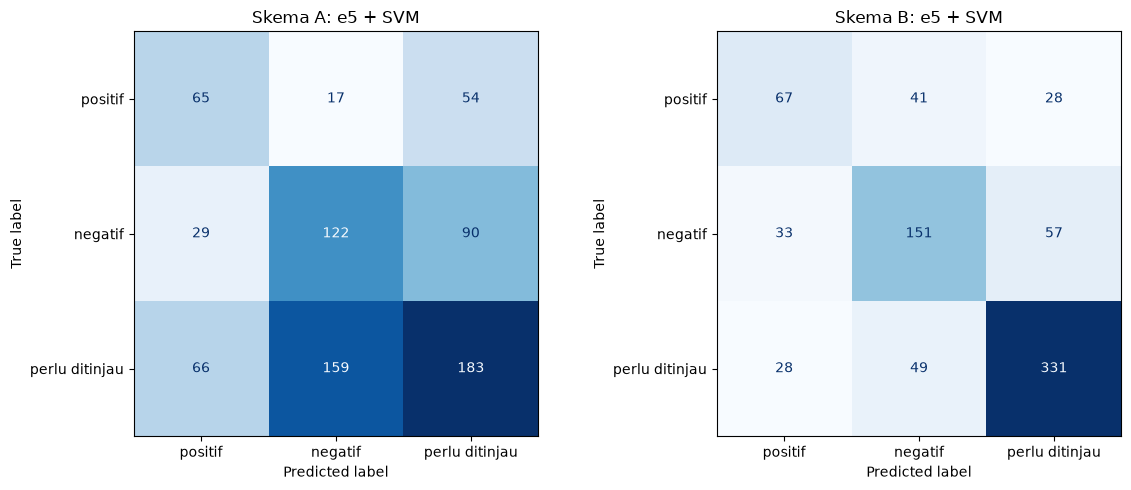

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for i, skema in enumerate(["A", "B"]):
    terbaik = max((k for k in akhir if k[0] == skema), key=lambda k: f1_score(y_test_3, akhir[k], average="macro"))
    print(f"===== Skema {skema}: {terbaik[1]} =====")
    print(classification_report(y_test_3, akhir[terbaik], digits=3))
    ConfusionMatrixDisplay.from_predictions(y_test_3, akhir[terbaik], labels=["positif", "negatif", TINJAU],
                                            cmap="Blues", ax=ax[i], colorbar=False)
    ax[i].set_title(f"Skema {skema}: {terbaik[1]}")
plt.tight_layout()
plt.show()

**Hasil:**

| Skema | Model | Pengaturan terbaik | Macro-F1 CV | Macro-F1 uji sebelum | Macro-F1 uji sesudah | Akurasi | Perlu ditinjau |
|---|---|---|---|---|---|---|---|
| **B** | **e5 + SVM** | `C` = 0,42 | 0,617 | 0,625 | **0,646** | **0,699** | 53,0% |
| B | e5 + Logistic Regression | `C` = 5,56 | 0,623 | 0,631 | 0,639 | 0,678 | 47,3% |
| A | e5 + SVM | `C` = 0,17, ambang 0,54 | 0,455 | 0,329 | 0,463 | 0,471 | 41,7% |
| A | e5 + Logistic Regression | `C` = 7,63, ambang 0,69 | 0,454 | 0,307 | 0,440 | 0,479 | 55,4% |
| A | TF-IDF + Logistic Regression | unigram, `min_df` = 2, `C` = 1,98, ambang 0,63 | 0,413 | 0,311 | 0,422 | 0,470 | 56,8% |

- Tuning **paling membantu skema A** (+0,11 sampai +0,13), terutama karena ambangnya diturunkan dari 0,7 menjadi 0,54-0,69. Meski begitu, skema A tetap jauh di bawah skema B.
- **Model akhir terbaik: skema B, e5 + SVM hasil tuning, macro-F1 0,646 dan akurasi 0,699.** Model ini menyerahkan 53% komentar ke "perlu ditinjau", hampir sama dengan proporsi sebenarnya di data uji (52%).

**Skor per label model terbaik setiap skema (data uji, 785 komentar):**

| Label | Skema A: precision | recall | F1 | Skema B: precision | recall | F1 |
|---|---|---|---|---|---|---|
| positif | 0,406 | 0,478 | 0,439 | 0,523 | 0,493 | 0,508 |
| negatif | 0,409 | 0,506 | 0,453 | 0,627 | 0,627 | 0,627 |
| perlu ditinjau | 0,560 | 0,449 | 0,498 | 0,796 | 0,811 | 0,803 |
| **macro** | **0,458** | **0,478** | **0,463** | **0,649** | **0,643** | **0,646** |

**Kesimpulan:**
- **Menyederhanakan label membantu, tetapi caranya menentukan.** Menggabungkan netral dan tidak relevan menjadi "perlu ditinjau" menaikkan skor model terbaik dari 0,582 (4 label) menjadi **0,646** (3 label). Kedua angka ini tidak sepenuhnya setara, karena tugas 3 label memang lebih mudah.
- **Melatih hanya dengan positif dan negatif (skema A) tidak berhasil.** Keraguan model bukan penanda yang baik untuk komentar yang perlu ditinjau. Model harus diberi contoh komentar seperti itu saat latihan (skema B).
- Label yang paling sulit sekarang adalah **positif** (F1 0,508). Jumlahnya paling sedikit, dan banyak komentar positif berupa sindiran atau argumen panjang yang mirip komentar negatif.

# **10. Rekomendasi Pengembangan**

Model akhir saat ini (skema B, e5 + SVM) mencapai **macro-F1 0,646, precision 0,649, dan recall 0,643** pada 3 label. Bab ini berisi langkah-langkah untuk menaikkannya ke kisaran **0,70-0,85**, diurutkan dari yang paling berpengaruh.

**Hal terpenting yang perlu dipahami dulu:** skor model tidak bisa jauh melampaui kualitas labelnya. Label saat ini dibuat oleh AI dengan kecocokan sekitar 0,60-0,68 terhadap label manual (Bab 5.4), dan model sudah mendekati batas itu. Jadi:

| Target | Yang dibutuhkan |
|---|---|
| **± 0,70** | cukup dengan perbaikan model dan cara klasifikasi (langkah 3-6) |
| **0,75-0,85** | **wajib** memperbaiki kualitas label (langkah 1-2), baru kemudian memperbaiki model |

## **10.1 Langkah 1: Perbaiki Kualitas Label (dampak terbesar)**

- **Labeli manual 300-500 komentar oleh 2 orang secara terpisah**, memakai panduan di Bab 5.1. Pilih komentar acak dari ketiga label, dan perbanyak komentar positif karena label ini paling lemah.
- **Ukur kesepakatan kedua orang** dengan Cohen's kappa (`sklearn.metrics.cohen_kappa_score`). Kalau kappa di bawah 0,6, panduannya masih kabur dan perlu dipertegas lagi sebelum melabeli lebih banyak.
- **Diskusikan komentar yang labelnya berbeda**, lalu tambahkan aturan baru ke panduan (seperti lima aturan di Bab 5.3).
- **Ganti label AI dengan label manual** untuk komentar yang sudah dilabeli ulang. Bisa juga melatih ulang pelabel AI dengan contoh-contoh baru ini, lalu melabeli ulang seluruh data.

Kalau dua manusia saja hanya sepakat sekitar 75%, angka itu adalah batas realistis untuk model. Target 0,85 hanya mungkin kalau kesepakatan manusia juga setinggi itu.

## **10.2 Langkah 2: Siapkan Data Uji yang Bersih**

- Data uji saat ini berlabel AI, dan bagian test gold set sudah dipakai untuk merumuskan aturan. Karena itu siapkan **100-200 komentar baru** yang belum pernah dipakai, lalu labeli manual (sebaiknya oleh 2 orang).
- Semua perbandingan berikutnya dinilai pada data uji bersih ini, supaya kenaikan skor bisa dipercaya.
- Laporkan juga skor **cross-validation (rata-rata ± simpangan baku)**, bukan hanya satu kali pembagian data, karena 785 komentar uji masih cukup kecil sehingga skornya bisa naik-turun beberapa persen.

## **10.3 Langkah 3: Klasifikasi Dua Tahap**

Pisahkan satu tugas sulit menjadi dua tugas yang lebih mudah:

| Tahap | Pertanyaan | Data latih |
|---|---|---|
| 1 | Apakah komentar ini **jelas sikapnya** atau **perlu ditinjau**? | semua komentar |
| 2 | Kalau jelas, **positif** atau **negatif**? | hanya positif dan negatif |

Tahap 1 sudah terbukti cukup mudah (F1 "perlu ditinjau" 0,80 di Bab 9), dan tahap 2 hanya membedakan dua label yang batasnya paling jelas. Implementasinya cukup dua model e5 + SVM yang dijalankan berurutan, memakai data di Bab 7.2 (`y_train_3` untuk tahap 1, `y_train_2` untuk tahap 2).

## **10.4 Langkah 4: Model dan Fitur yang Lebih Kuat**

- **Embedding yang lebih besar.** Ganti `intfloat/multilingual-e5-base` di 8.3 dengan `intfloat/multilingual-e5-large` atau `BAAI/bge-m3`. Keduanya multibahasa (Indonesia dan Inggris), dan cukup mengganti satu baris kode.
- **SetFit.** Metode *fine-tuning* untuk model *sentence-transformers* yang dirancang untuk data berlabel sedikit (ratusan sampai beberapa ribu komentar). Library: `setfit`.
- ***Fine-tuning* yang lebih serius di Google Colab** (GPU T4 atau lebih besar). Jangan bekukan lapisan embedding, latih 5-10 epoch, dan pakai sebagian data latih sebagai validasi untuk *early stopping*. Pada laptop dengan GPU 6 GB, XLM-RoBERTa terbukti tidak stabil (Bab 8.2).
- **Gabungkan fitur.** Tempelkan vektor TF-IDF (dengan bigram) di samping vektor e5, karena TF-IDF menangkap kata kunci seperti "not replace", sedangkan e5 menangkap makna kalimat.

## **10.5 Langkah 5: Atasi Label Positif yang Lemah**

Positif adalah label dengan F1 terendah (0,508) dan jumlah paling sedikit (17%).

- **Tambah data positif.** Ambil komentar dari video yang lebih banyak membahas sisi optimis AI, lalu labeli.
- **Geser ambang per label.** Setelah model skema B memberi peluang untuk tiap label, naikkan sedikit bobot label positif dan cari nilai terbaiknya dengan cross-validation di data latih (bukan di data uji), seperti pencarian ambang di Bab 9.
- **Periksa contoh yang salah tebak.** Tampilkan komentar positif yang tertebak negatif. Kalau ternyata labelnya yang keliru, kembali ke langkah 1.

## **10.6 Langkah 6: Gabungkan Beberapa Model (Ensemble)**

Gabungkan tebakan beberapa model terbaik, misalnya e5 + SVM, e5 + Logistic Regression, dan TF-IDF + Logistic Regression, dengan `sklearn.ensemble.VotingClassifier` (voting berdasarkan peluang). Model yang berbeda sering salah pada komentar yang berbeda, sehingga gabungannya biasanya sedikit lebih stabil.

## **10.7 Urutan Pengerjaan yang Disarankan**

1. Langkah 2 dulu (data uji bersih), supaya setiap perubahan bisa diukur dengan jujur.
2. Langkah 3 dan 4 (dua tahap + embedding lebih besar): paling cepat dicoba, kemungkinan cukup untuk mencapai sekitar 0,70.
3. Langkah 1 dan 5 (kualitas label dan label positif): paling banyak tenaga, tetapi satu-satunya jalan menuju 0,80-0,85.
4. Langkah 6 terakhir, sebagai penyempurnaan.

Semua perkiraan di atas adalah **dugaan** berdasarkan hasil notebook ini, dan harus dibuktikan dengan percobaan.